# 03 Exploratory Data Analysis and Feature Engineering

**Project:** CreditLens, SME credit risk scoring for guaranteed loans
**CRISP-DM phase:** Data Preparation (brief stage 4: feature engineering), with the exploratory analysis that motivates it
**Author:** Sultan Zayed Ahmed Saeed Alkindi

**Purpose.** Notebook 02 gave us a clean table of 895,952 loans with a known outcome. Here we explore it as a credit officer would, asking which kinds of loans are charged off and why, and we turn what we learn into features. Every feature in section 6 of the brief is built in `src/features.py`, explained with the reason for it, and then tested for value in three ways: the spread of default rates across its values, its mutual information with the target, and an ablation that compares a quick LightGBM model on the raw cleaned columns with the same model on raw plus engineered features. The single train/test split used by every later notebook is also fixed here.

**Inputs:** `data/processed/loans_clean.parquet`.

**Outputs:** `data/processed/loans_features.parquet`, `data/processed/test_ids.parquet`, `models/feature_schema.json`, `docs/feature_value_tests.csv`, `docs/feature_ablation.csv`, `docs/eda_findings.md` and figures `docs/figures/fig03_*.png`.

## 1. Setup

As in the earlier notebooks, we add the repository root to the path and take every location and constant from `src/config.py`. Two small helpers compute default rates by group and save figures in the house style.

In [1]:
import sys
import json
import time
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from lightgbm import LGBMClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

from src import config
from src import features as fe
from src import modelling as md

NOTEBOOK_START = time.time()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})
P = config.PALETTE
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
config.MODELS_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    """Save a figure to docs/figures at 150 dpi and print the relative path."""
    path = config.FIGURES_DIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Saved {path.relative_to(config.PROJECT_ROOT)}")


def rate_table(data, by, min_loans=0):
    """Loans, defaults and default rate (%) for each value of ``by``."""
    t = data.groupby(by, observed=True)[config.TARGET].agg(loans="size", defaults="sum")
    t["default_rate_pct"] = 100 * t["defaults"] / t["loans"]
    t["share_pct"] = 100 * t["loans"] / len(data)
    return t[t["loans"] >= min_loans]


def pct_axis(ax, axis="y"):
    """Format an axis as percentages."""
    fmt = mtick.PercentFormatter(decimals=0)
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)

## 2. Load the clean data and build the row-level features

We load the output of notebook 02 and immediately call `build_features()`. This is safe before the split because every feature it creates uses only the loan's own row (for example `Portion` is that loan's `SBA_Appv / GrAppv`). The two bank features are different: they summarise the outcomes of other loans from the same bank, so they are learned later from the training rows only.

In [2]:
clean = pd.read_parquet(config.CLEAN_DATA_PATH)
print(f"Loaded {config.CLEAN_DATA_PATH.relative_to(config.PROJECT_ROOT)}: {clean.shape[0]:,} rows, {clean.shape[1]} columns")
print(f"Default rate: {clean[config.TARGET].mean():.2%}")

t0 = time.time()
feats = fe.build_features(clean)
print(f"build_features added {feats.shape[1] - clean.shape[1]} columns in {time.time() - t0:.1f} s")

# The columns that must never reach a model
print("Never used as features:", fe.EXCLUDED_COLUMNS)
assert not set(fe.FEATURE_COLUMNS) & set(fe.EXCLUDED_COLUMNS)

Loaded data/processed/loans_clean.parquet: 895,952 rows, 35 columns
Default rate: 17.56%


build_features added 16 columns in 3.8 s
Never used as features: ['BalanceGross', 'ChgOffDate', 'ChgOffPrinGr', 'City', 'LoanNr_ChkDgt', 'MIS_Status', 'Name', 'RevLineCr_raw', 'Zip', 'chgoff_mismatch', 'date_out_of_range', 'disb_before_approval', 'noemp_imputed', 'state_from_zip', 'term_imputed']


## 3. Fix the train/test split before looking at the data

The brief asks for one stratified 80/20 split, made once and shared by every notebook and the app. We make it here, before any exploration, and do all of the analysis below on the training part only. The test loans stay unseen until notebook 05, so nothing we decide in this notebook can be tuned to them. `split_data()` writes the test loan numbers to `data/processed/test_ids.parquet`; later notebooks read that file and get exactly the same test set.

In [3]:
X_train_all, X_test_all, y_train, y_test = md.split_data(
    feats, feature_columns=list(feats.columns), save_ids=True, reuse_saved=False
)
print(f"Train: {len(X_train_all):,} loans, default rate {y_train.mean():.2%}")
print(f"Test:  {len(X_test_all):,} loans, default rate {y_test.mean():.2%}")

# A second call that reads the saved file must give the identical split
_, X_test_check, _, _ = md.split_data(feats, feature_columns=["LoanNr_ChkDgt"], reuse_saved=True)
assert X_test_check.index.equals(X_test_all.index)
print("Saved test ids reproduce the split:", md.TEST_IDS_PATH.relative_to(config.PROJECT_ROOT))

train = feats.loc[X_train_all.index].copy()
overall = 100 * train[config.TARGET].mean()

Train: 716,761 loans, default rate 17.56%
Test:  179,191 loans, default rate 17.57%
Saved test ids reproduce the split: data/processed/test_ids.parquet


## 4. Exploratory data analysis

We follow the questions a credit committee would ask: which industries, which years, which loan sizes and structures, which places and which kinds of borrower default most. Default rate always means the share of loans charged off, in per cent, on the 716,761 training loans; the dashed line in each chart is the overall training default rate.

### 4.1 Industry sector

Saved docs/figures/fig03_default_rate_by_sector.png


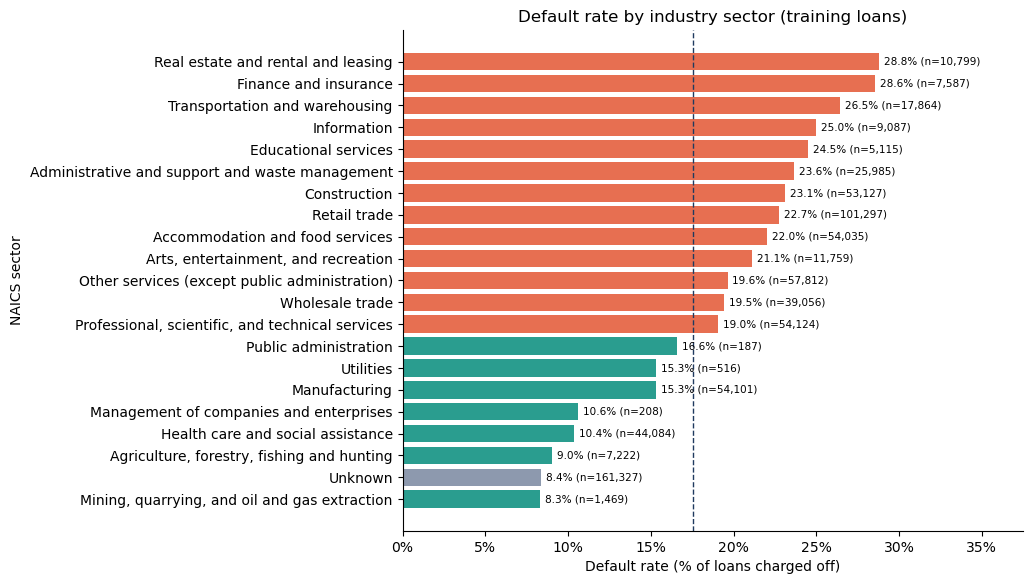

,loans,default_rate_pct
Sector,,
Real estate and rental and leasing,10799,28.817
Finance and insurance,7587,28.575
Transportation and warehousing,17864,26.461
Information,9087,24.970
Educational services,5115,24.497
Administrative and support and waste management,25985,23.641
Construction,53127,23.114
Retail trade,101297,22.726
Accommodation and food services,54035,22.017


In [4]:
sector = rate_table(train, "Sector").sort_values("default_rate_pct")
fig, ax = plt.subplots(figsize=(8, 6.5))
colours = [P["grey"] if s == config.UNKNOWN_SECTOR else (P["red"] if r > overall else P["teal"])
           for s, r in zip(sector.index, sector["default_rate_pct"])]
ax.barh(sector.index, sector["default_rate_pct"], color=colours)
ax.axvline(overall, color=P["navy"], ls="--", lw=1)
for i, (r, n) in enumerate(zip(sector["default_rate_pct"], sector["loans"])):
    ax.text(r + 0.3, i, f"{r:.1f}% (n={n:,})", va="center", fontsize=7.5)
ax.set_xlabel("Default rate (% of loans charged off)")
ax.set_ylabel("NAICS sector")
ax.set_title("Default rate by industry sector (training loans)")
pct_axis(ax, "x")
ax.set_xlim(0, sector["default_rate_pct"].max() * 1.3)
save_fig(fig, "fig03_default_rate_by_sector.png")
plt.show()
sector[["loans", "default_rate_pct"]].sort_values("default_rate_pct", ascending=False)

Industry matters a great deal: real estate and rental (28.8%) and finance and insurance (28.6%) are charged off at roughly three times the rate of health care (10.4%) and agriculture (9.0%), and the large retail and food service books sit well above the 17.6% average. The 161,327 loans with no industry code default at only 8.4%; almost all of them were approved in 2000 or earlier (median approval year 1995), before industry codes were recorded for every loan, so `Unknown` is partly a marker of approval period rather than of industry, which is why we keep it as its own level instead of guessing a sector.

### 4.2 Approval year and right-censoring

Saved docs/figures/fig03_default_rate_by_approval_year.png


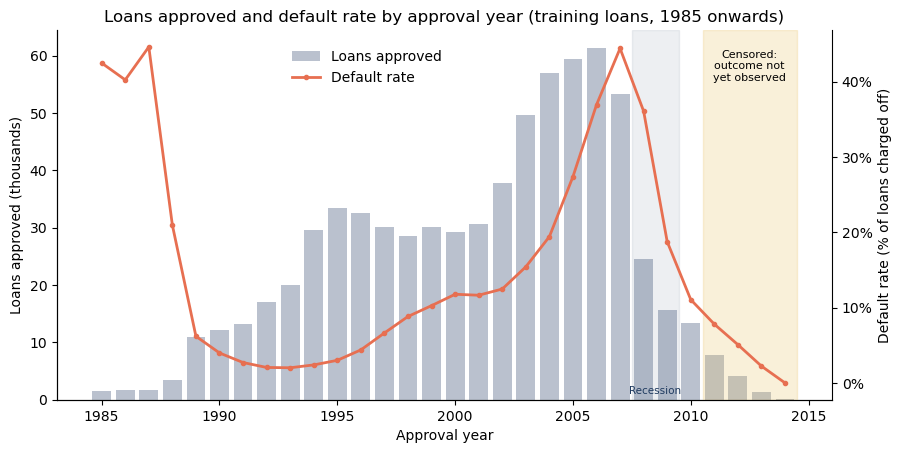

Loans approved before 1985 (not shown): 5,485


,loans,default_rate_pct
ApprovalYear,,
1985,1591,42.489
1986,1744,40.252
1987,1712,44.626
1990,12088,3.979
1995,33421,3.001
2000,29267,11.774
2003,49568,15.421
2005,59454,27.398
2006,61381,36.938


In [5]:
year = rate_table(train, "ApprovalYear")
year = year.loc[1985:]  # earlier years hold very few loans
fig, ax1 = plt.subplots(figsize=(10, 4.8))
ax1.bar(year.index, year["loans"] / 1000, color=P["grey"], alpha=0.6, label="Loans approved")
ax1.set_xlabel("Approval year")
ax1.set_ylabel("Loans approved (thousands)")
ax2 = ax1.twinx()
ax2.plot(year.index, year["default_rate_pct"], color=P["red"], marker="o", ms=3, lw=2, label="Default rate")
ax2.set_ylabel("Default rate (% of loans charged off)")
ax2.spines["right"].set_visible(True)
pct_axis(ax2)
ax2.axvspan(2010.5, 2014.5, color=P["amber"], alpha=0.25)
ax2.text(2012.5, year["default_rate_pct"].max() * 0.9, "Censored:\noutcome not\nyet observed", ha="center", fontsize=8)
ax2.axvspan(2007.5, 2009.5, color=P["navy"], alpha=0.08)
ax2.text(2008.5, -1.5, "Recession", ha="center", fontsize=7.5, color=P["navy"])
ax1.set_title("Loans approved and default rate by approval year (training loans, 1985 onwards)")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.4, 0.98), frameon=False)
save_fig(fig, "fig03_default_rate_by_approval_year.png")
plt.show()
print(f"Loans approved before 1985 (not shown): {(train['ApprovalYear'] < 1985).sum():,}")
year.loc[[1985, 1986, 1987, 1990, 1995, 2000, 2003, 2005, 2006, 2007, 2008, 2010, 2012, 2013], ["loans", "default_rate_pct"]]

The default rate follows the lending cycle: it was 3 to 4% for loans approved in the early and mid 1990s, climbed to 27.4% in 2005, 36.9% in 2006 and 44.4% in 2007, and fell back to 11.1% in 2010 and 2.2% in 2013. Loans approved in 1985 to 1987 also show rates above 40%, but these years hold fewer than 2,000 training loans each and probably reflect which older records were kept in the database, so we do not read them as a lending-cycle effect. The pre-crisis peak is real credit risk (loans written in the boom and then hit by the recession), but the fall after 2010 is mostly right-censoring: when the data was extracted in 2014 a recent loan could only be recorded as charged off or as paid in full early, so ApprovalYear partly measures how much of the loan's life we have observed. Notebook 05 therefore adds a temporal validation, and the model's use of ApprovalYear must be read with this in mind.

### 4.3 Loan size

Saved docs/figures/fig03_default_rate_by_loan_size.png


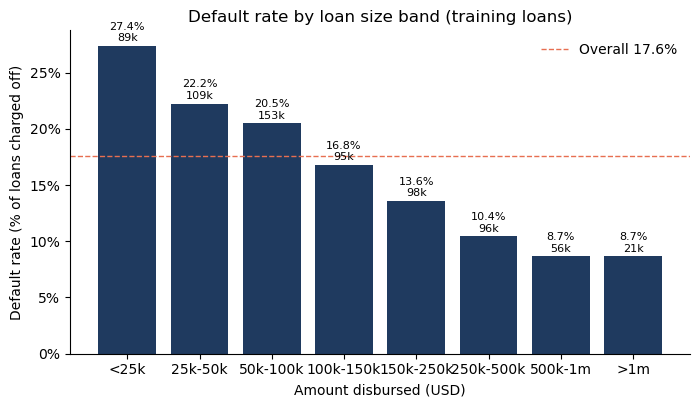

,loans,default_rate_pct
SizeBand,,
<25k,89077,27.381
25k-50k,108783,22.242
50k-100k,153445,20.474
100k-150k,94637,16.803
150k-250k,97701,13.600
250k-500k,95767,10.441
500k-1m,56288,8.664
>1m,21063,8.688


In [6]:
size_bins = [0, 25_000, 50_000, 100_000, 150_000, 250_000, 500_000, 1_000_000, np.inf]
size_labels = ["<25k", "25k-50k", "50k-100k", "100k-150k", "150k-250k", "250k-500k", "500k-1m", ">1m"]
train["SizeBand"] = pd.cut(train["DisbursementGross"], size_bins, labels=size_labels, right=False)
size = rate_table(train, "SizeBand")
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(size.index.astype(str), size["default_rate_pct"], color=P["navy"])
ax.axhline(overall, color=P["red"], ls="--", lw=1, label=f"Overall {overall:.1f}%")
for i, (r, n) in enumerate(zip(size["default_rate_pct"], size["loans"])):
    ax.text(i, r + 0.4, f"{r:.1f}%\n{n/1000:.0f}k", ha="center", fontsize=8)
ax.set_xlabel("Amount disbursed (USD)")
ax.set_ylabel("Default rate (% of loans charged off)")
ax.set_title("Default rate by loan size band (training loans)")
pct_axis(ax)
ax.legend(frameon=False)
save_fig(fig, "fig03_default_rate_by_loan_size.png")
plt.show()
size[["loans", "default_rate_pct"]]

Risk falls steadily with loan size, from 27.4% for loans under USD 25,000 to 8.7% above USD 500,000. For a bank this is a useful counterweight to intuition: the small loans that look harmless one by one carry three times the default rate, although each one costs less when it fails, which the cost matrix in notebook 05 accounts for.

### 4.4 Loan term and the real-estate cut at 240 months

Saved docs/figures/fig03_default_rate_by_term.png


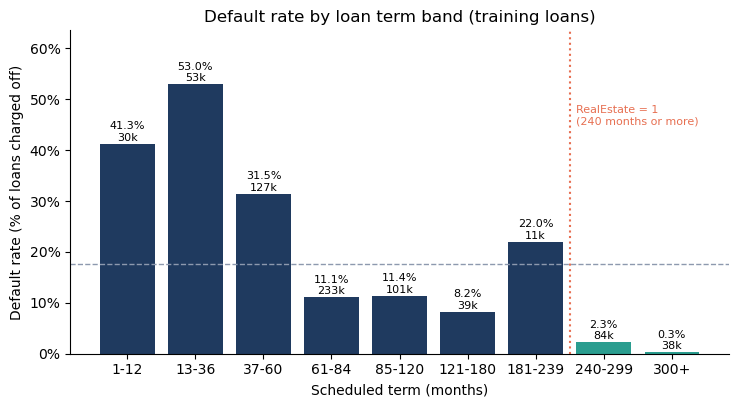

,loans,default_rate_pct
TermBand,,
1-12,30480,41.257
13-36,53233,52.973
37-60,127396,31.480
61-84,232857,11.104
85-120,101037,11.370
121-180,38831,8.243
181-239,11202,21.987
240-299,83529,2.275
300+,38196,0.291


In [7]:
term_bins = [0, 13, 37, 61, 85, 121, 181, 240, 300, np.inf]
term_labels = ["1-12", "13-36", "37-60", "61-84", "85-120", "121-180", "181-239", "240-299", "300+"]
train["TermBand"] = pd.cut(train["Term"], term_bins, labels=term_labels, right=False)
term = rate_table(train, "TermBand")
fig, ax = plt.subplots(figsize=(8.5, 4.2))
colours = [P["teal"] if lab in ("240-299", "300+") else P["navy"] for lab in term.index.astype(str)]
ax.bar(term.index.astype(str), term["default_rate_pct"], color=colours)
ax.axvline(6.5, color=P["red"], ls=":", lw=1.5)
ax.text(6.6, term["default_rate_pct"].max() * 0.85, "RealEstate = 1\n(240 months or more)", fontsize=8, color=P["red"])
ax.axhline(overall, color=P["grey"], ls="--", lw=1)
for i, (r, n) in enumerate(zip(term["default_rate_pct"], term["loans"])):
    ax.text(i, r + 0.6, f"{r:.1f}%\n{n/1000:.0f}k", ha="center", fontsize=8)
ax.set_xlabel("Scheduled term (months)")
ax.set_ylabel("Default rate (% of loans charged off)")
ax.set_title("Default rate by loan term band (training loans)")
pct_axis(ax)
ax.set_ylim(0, term["default_rate_pct"].max() * 1.2)
save_fig(fig, "fig03_default_rate_by_term.png")
plt.show()
term[["loans", "default_rate_pct"]]

Term is the sharpest single divide in the data. Loans of 13 to 36 months default at 53.0% and loans of 1 to 12 months at 41.3%, while 61 to 120 months sits at about 11%; above the 240-month line the rate drops to 2.3% (240 to 299 months) and 0.3% (300 months or more), which is the real-estate collateral effect that `RealEstate` captures. The 181 to 239 month band (22.0%) breaks the downward trend, so the relationship is not monotonic and a tree model will use it better than a linear one. The gap between short and long terms is larger than credit experience alone would suggest, and we cannot rule out that for some charged-off loans the recorded term reflects the shortened life of the loan rather than the term agreed at approval; notebooks 04 and 05 should check how much the model relies on Term.

### 4.5 Guaranteed portion

Saved docs/figures/fig03_default_rate_by_portion.png


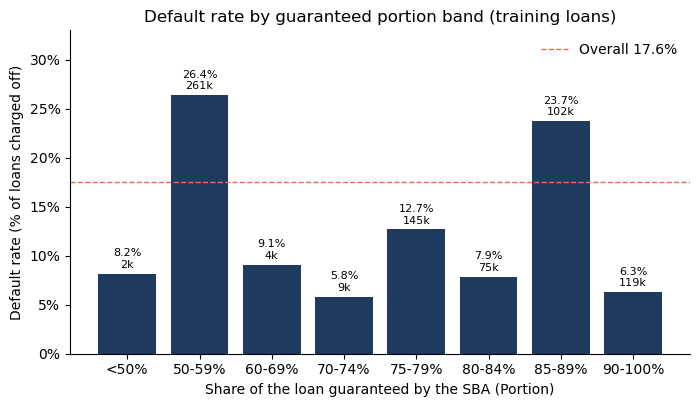

,loans,default_rate_pct
PortionBand,,
<50%,1962,8.155
50-59%,260756,26.402
60-69%,4078,9.098
70-74%,9487,5.818
75-79%,144860,12.681
80-84%,74806,7.870
85-89%,102266,23.735
90-100%,118546,6.275


In [8]:
portion_bins = [0, 0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 1.01]
portion_labels = ["<50%", "50-59%", "60-69%", "70-74%", "75-79%", "80-84%", "85-89%", "90-100%"]
train["PortionBand"] = pd.cut(train["Portion"], portion_bins, labels=portion_labels, right=False)
portion = rate_table(train, "PortionBand")
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(portion.index.astype(str), portion["default_rate_pct"], color=P["navy"])
ax.axhline(overall, color=P["red"], ls="--", lw=1, label=f"Overall {overall:.1f}%")
for i, (r, n) in enumerate(zip(portion["default_rate_pct"], portion["loans"])):
    ax.text(i, r + 0.6, f"{r:.1f}%\n{n/1000:.0f}k", ha="center", fontsize=8)
ax.set_xlabel("Share of the loan guaranteed by the SBA (Portion)")
ax.set_ylabel("Default rate (% of loans charged off)")
ax.set_title("Default rate by guaranteed portion band (training loans)")
pct_axis(ax)
ax.set_ylim(0, portion["default_rate_pct"].max() * 1.25)
ax.legend(frameon=False)
save_fig(fig, "fig03_default_rate_by_portion.png")
plt.show()
portion[["loans", "default_rate_pct"]]

The guaranteed share does not move smoothly with risk. Loans with a 50 to 59% guarantee (26.4% default) and 85 to 89% guarantee (23.7%) are far riskier than those at 80 to 84% (7.9%) or 90% and above (6.3%). These bands correspond to programme rules rather than a judgement about the borrower: in our training data the share of loans with a 50% guarantee rose from 10% of 1997 approvals to 72% of 2006 approvals, the period of the express programme with its lower guarantee and lighter checks. `Portion` therefore carries information about the loan programme and era as well as the bank's exposure.

### 4.6 Borrower state

Saved docs/figures/fig03_default_rate_by_state.png


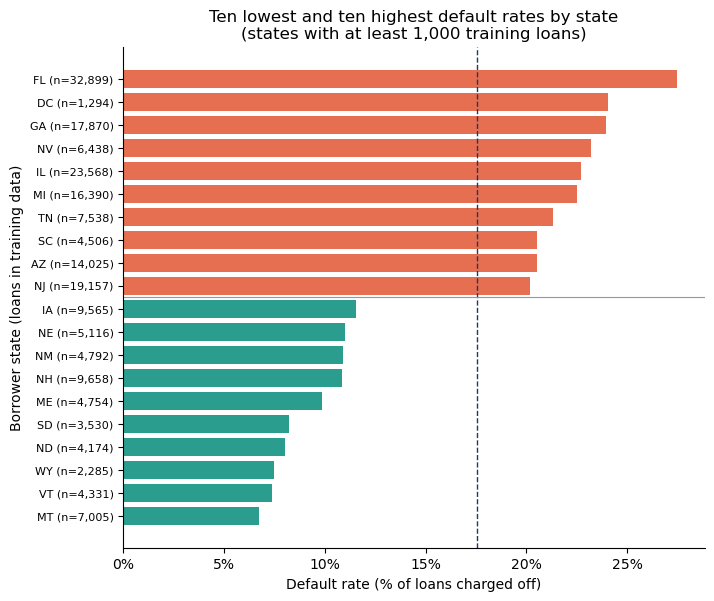

States shown from 51 with 1,000+ loans; range 6.7% to 27.5%


loans  default_rate_pct
group   State                         
lowest  MT      7005             6.738
        VT      4331             7.389
        WY      2285             7.484
        ND      4174             8.002
        SD      3530             8.244
        ME      4754             9.865
        NH      9658            10.830
        NM      4792            10.914
        NE      5116            11.024
        IA      9565            11.563
highest NJ     19157            20.165
        AZ     14025            20.535
        SC      4506            20.550
        TN      7538            21.305
        MI     16390            22.538
        IL     23568            22.709
        NV      6438            23.190
        GA     17870            23.973
        DC      1294            24.034
        FL     32899            27.469

In [9]:
state = rate_table(train, "State", min_loans=1000).sort_values("default_rate_pct")
low10, high10 = state.head(10), state.tail(10)
both = pd.concat([low10, high10])
fig, ax = plt.subplots(figsize=(7.5, 6.5))
colours = [P["teal"]] * 10 + [P["red"]] * 10
ax.barh(range(20), both["default_rate_pct"], color=colours)
ax.set_yticks(range(20), [f"{s} (n={n:,})" for s, n in zip(both.index, both["loans"])], fontsize=8)
ax.axvline(overall, color=P["navy"], ls="--", lw=1)
ax.axhline(9.5, color=P["grey"], lw=0.8)
ax.set_xlabel("Default rate (% of loans charged off)")
ax.set_ylabel("Borrower state (loans in training data)")
ax.set_title("Ten lowest and ten highest default rates by state\n(states with at least 1,000 training loans)")
pct_axis(ax, "x")
save_fig(fig, "fig03_default_rate_by_state.png")
plt.show()
print(f"States shown from {len(state)} with 1,000+ loans; range {state['default_rate_pct'].min():.1f}% to {state['default_rate_pct'].max():.1f}%")
pd.concat({"lowest": low10, "highest": high10}, names=["group", "State"])[["loans", "default_rate_pct"]]

Location matters: among the 51 states with at least 1,000 training loans, default rates range from 6.7% in Montana to 27.5% in Florida, a factor of four. The low-risk group is dominated by rural northern states (Montana, Vermont, Wyoming, the Dakotas), while the high-risk group includes Florida, Georgia, Nevada, Illinois and Michigan, several of which had the deepest housing and employment falls of the 2008 crisis.

### 4.7 Borrower profile: business age, franchise and lender location

Three yes-or-no facts about the borrower that a loan officer knows at application: whether the business is new, whether it is a franchise and whether the bank is in the same state.

Saved docs/figures/fig03_default_rate_by_borrower_profile.png


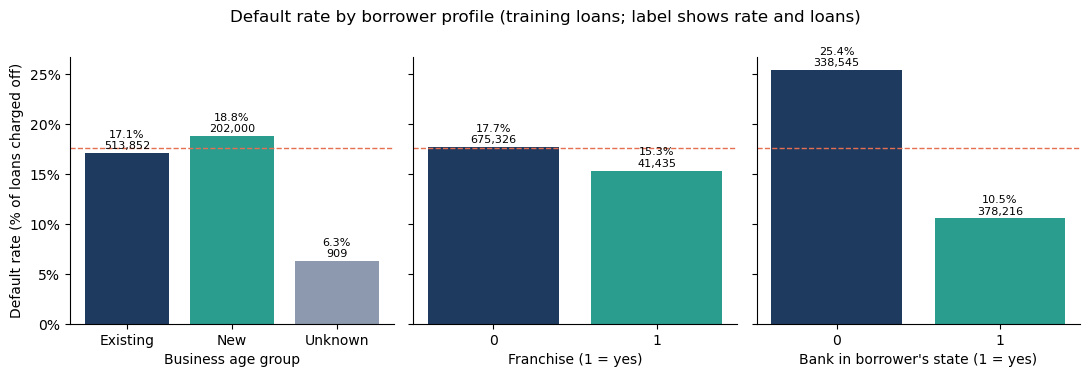

loans  default_rate_pct
feature       value                             
NewExist      Existing  513852            17.104
              New       202000            18.788
              Unknown      909             6.271
IsFranchise   0         675326            17.703
              1          41435            15.316
SameStateBank 0         338545            25.404
              1         378216            10.547

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True)
panels = [
    ("NewExist", "Business age group", ["Existing", "New", "Unknown"]),
    ("IsFranchise", "Franchise (1 = yes)", [0, 1]),
    ("SameStateBank", "Bank in borrower's state (1 = yes)", [0, 1]),
]
profile = {}
for ax, (col, label, order) in zip(axes, panels):
    t = rate_table(train, col).reindex(order)
    profile[col] = t
    ax.bar([str(v) for v in t.index], t["default_rate_pct"], color=[P["navy"], P["teal"], P["grey"]][: len(t)])
    for i, (r, n) in enumerate(zip(t["default_rate_pct"], t["loans"])):
        ax.text(i, r + 0.4, f"{r:.1f}%\n{n:,}", ha="center", fontsize=8)
    ax.axhline(overall, color=P["red"], ls="--", lw=1)
    ax.set_xlabel(label)
    pct_axis(ax)
axes[0].set_ylabel("Default rate (% of loans charged off)")
fig.suptitle("Default rate by borrower profile (training loans; label shows rate and loans)")
fig.tight_layout()
save_fig(fig, "fig03_default_rate_by_borrower_profile.png")
plt.show()
pd.concat(profile, names=["feature", "value"])[["loans", "default_rate_pct"]]

New businesses default slightly more than existing ones (18.8% against 17.1%), a smaller gap than we expected, and franchises slightly less (15.3% against 17.7%). The striking result is lender location: when the bank is in another state the default rate is 25.4%, against 10.5% when bank and borrower share a state. Out-of-state loans are smaller (median USD 75,000 against USD 120,000) and more recent (median approval year 2004 against 2000), so part of this gap reflects national lenders writing many small express loans, but it is large enough to justify `SameStateBank`.

### 4.8 Revolving credit, LowDoc and the urban or rural code

These are the coded columns repaired in notebook 02. For `RevLineCr` we show the raw code `T` separately from `Y`, because cleaning merged it into `Y` and section 5.3 tests whether that merge loses information.

Saved docs/figures/fig03_default_rate_by_revline_lowdoc.png


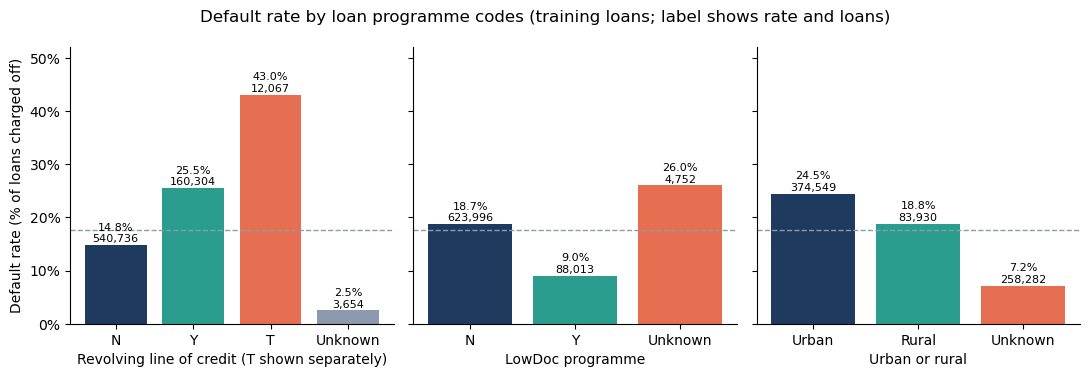

loans  default_rate_pct
feature    value                            
RevLineCr  N        540736            14.760
           Y        160304            25.450
           T         12067            43.043
           Unknown    3654             2.490
LowDoc     N        623996            18.706
           Y         88013             9.019
           Unknown    4752            25.989
UrbanRural Urban    374549            24.467
           Rural     83930            18.810
           Unknown  258282             7.151

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True)
codes = {}
for ax, (col, label, order) in zip(axes, [
    ("RevLineCr", "Revolving line of credit (T shown separately)", ["N", "Y", "T", "Unknown"]),
    ("LowDoc", "LowDoc programme", ["N", "Y", "Unknown"]),
    ("UrbanRural", "Urban or rural", ["Urban", "Rural", "Unknown"]),
]):
    t = rate_table(train, col).reindex(order)
    codes[col] = t
    ax.bar(t.index, t["default_rate_pct"], color=[P["navy"], P["teal"], P["red"], P["grey"]][: len(t)])
    for i, (r, n) in enumerate(zip(t["default_rate_pct"], t["loans"])):
        ax.text(i, r + 0.6, f"{r:.1f}%\n{n:,}", ha="center", fontsize=8)
    ax.axhline(overall, color=P["grey"], ls="--", lw=1)
    ax.set_xlabel(label)
    pct_axis(ax)
axes[0].set_ylabel("Default rate (% of loans charged off)")
axes[0].set_ylim(0, 52)
fig.suptitle("Default rate by loan programme codes (training loans; label shows rate and loans)")
fig.tight_layout()
save_fig(fig, "fig03_default_rate_by_revline_lowdoc.png")
plt.show()
pd.concat(codes, names=["feature", "value"])[["loans", "default_rate_pct"]]

Loans with a revolving line of credit default more than term loans (25.5% for Y against 14.8% for N), and the raw code `T`, which cleaning merged into Y, defaults at 43.0%. LowDoc loans, approved on a one-page application, default less (9.0%) than full-documentation loans (18.7%), probably because the programme was used for small, simple loans in the 1990s (median amount USD 60,000, median approval year 1997), when default rates were low. The Unknown levels behave very differently from the main levels (UrbanRural Unknown 7.2%, LowDoc Unknown 26.0%, RevLineCr Unknown 2.5%), which confirms the cleaning decision in notebook 02 to keep Unknown as a category instead of imputing the most common value.

### 4.9 Loans active during the Great Recession

Saved docs/figures/fig03_default_rate_by_recession.png


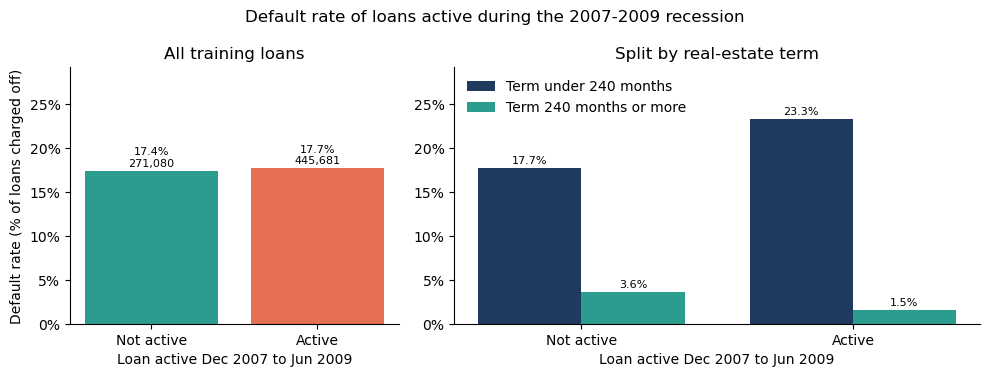

loans  default_rate_pct
RealEstate Recession                          
0          0          264696            17.694
           1          330340            23.325
1          0            6384             3.556
           1          115341             1.547

In [12]:
rec = rate_table(train, ["RealEstate", "Recession"])
rec_all = rate_table(train, "Recession")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].bar(["Not active", "Active"], rec_all["default_rate_pct"], color=[P["teal"], P["red"]])
for i, (r, n) in enumerate(zip(rec_all["default_rate_pct"], rec_all["loans"])):
    axes[0].text(i, r + 0.5, f"{r:.1f}%\n{n:,}", ha="center", fontsize=8)
axes[0].set_xlabel("Loan active Dec 2007 to Jun 2009")
axes[0].set_ylabel("Default rate (% of loans charged off)")
axes[0].set_title("All training loans")
pct_axis(axes[0])
width = 0.38
for k, (re_flag, name) in enumerate([(0, "Term under 240 months"), (1, "Term 240 months or more")]):
    vals = rec.loc[re_flag, "default_rate_pct"].reindex([0, 1])
    xs = np.arange(2) + (k - 0.5) * width
    axes[1].bar(xs, vals, width, color=[P["navy"], P["teal"]][k], label=name)
    for x, v in zip(xs, vals):
        axes[1].text(x, v + 0.5, f"{v:.1f}%", ha="center", fontsize=8)
axes[1].set_xticks(range(2), ["Not active", "Active"])
axes[1].set_xlabel("Loan active Dec 2007 to Jun 2009")
axes[1].set_title("Split by real-estate term")
axes[1].legend(frameon=False)
pct_axis(axes[1])
for ax in axes:
    ax.set_ylim(0, max(rec["default_rate_pct"].max(), rec_all["default_rate_pct"].max()) * 1.25)
fig.suptitle("Default rate of loans active during the 2007-2009 recession")
fig.tight_layout()
save_fig(fig, "fig03_default_rate_by_recession.png")
plt.show()
rec[["loans", "default_rate_pct"]]

Taken across all loans, being active during the recession seems to make no difference (17.7% against 17.4%), but that is a mix of two opposite groups. Among loans with a term under 240 months, those running through the recession default at 23.3% against 17.7%; among real-estate loans the active group defaults at 1.5% against 3.6%, but the inactive real-estate loans are a mix of loans approved before 1988 (7.1% default) and loans approved from 2009 onwards that are still too young to have failed (0.9%), so that comparison is really about approval period. `Recession` is therefore only useful together with term, which is a pattern a tree model can learn and a reason to keep both.

### 4.10 Distributions of loan amounts

Loan amounts span four orders of magnitude, so we plot them on a log scale and compare repaid and charged-off loans.

Saved docs/figures/fig03_log_amount_distributions.png


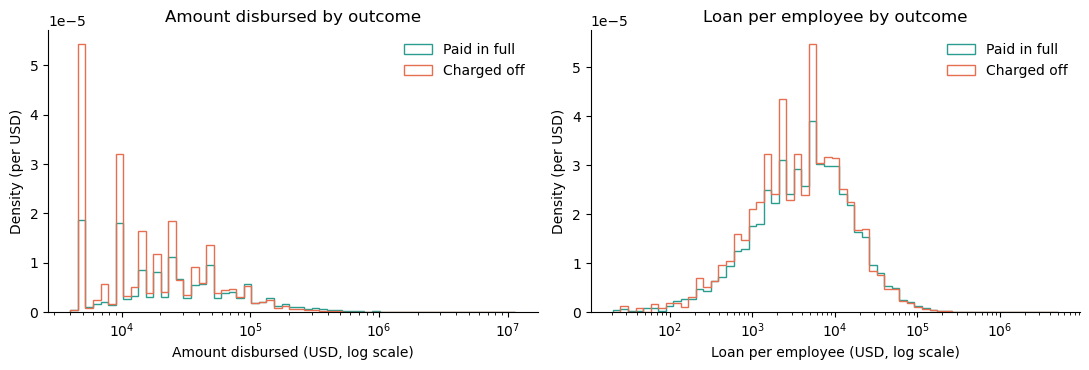

,DisbursementGross,LoanPerEmployee,NoEmp
Default,,,
0,"100,000.000","20,250.000",5.000
1,"61,484.000","17,866.667",3.000


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (col, label) in zip(axes, [("DisbursementGross", "Amount disbursed (USD, log scale)"),
                                    ("LoanPerEmployee", "Loan per employee (USD, log scale)")]):
    bins = np.logspace(np.log10(train[col].min()), np.log10(train[col].max()), 60)
    for flag, name, colour in [(0, "Paid in full", P["teal"]), (1, "Charged off", P["red"])]:
        ax.hist(train.loc[train[config.TARGET] == flag, col], bins=bins, density=True, histtype="step",
                lw=1.8, color=colour, label=name)
    ax.set_xscale("log")
    ax.set_xlabel(label)
    ax.set_ylabel("Density (per USD)")
    ax.legend(frameon=False)
axes[0].set_title("Amount disbursed by outcome")
axes[1].set_title("Loan per employee by outcome")
fig.tight_layout()
save_fig(fig, "fig03_log_amount_distributions.png")
plt.show()
train.groupby(config.TARGET)[["DisbursementGross", "LoanPerEmployee", "NoEmp"]].median()

On a log scale both amounts are roughly bell shaped, so the log transform used in `LogDisbursement` is appropriate for the linear model. Charged-off loans are clearly shifted towards smaller amounts (median USD 61,484 against USD 100,000) and smaller firms (median 3 employees against 5), while loan per employee differs much less (USD 17,867 against USD 20,250), so the size of the loan says more than how much debt each employee carries.

### 4.11 Correlation between numeric features

We use Spearman rank correlation because most amounts are heavily skewed and the relationships we care about are monotonic rather than linear. The target is included as the last row so its correlations can be read off directly.

Saved docs/figures/fig03_correlation_heatmap.png


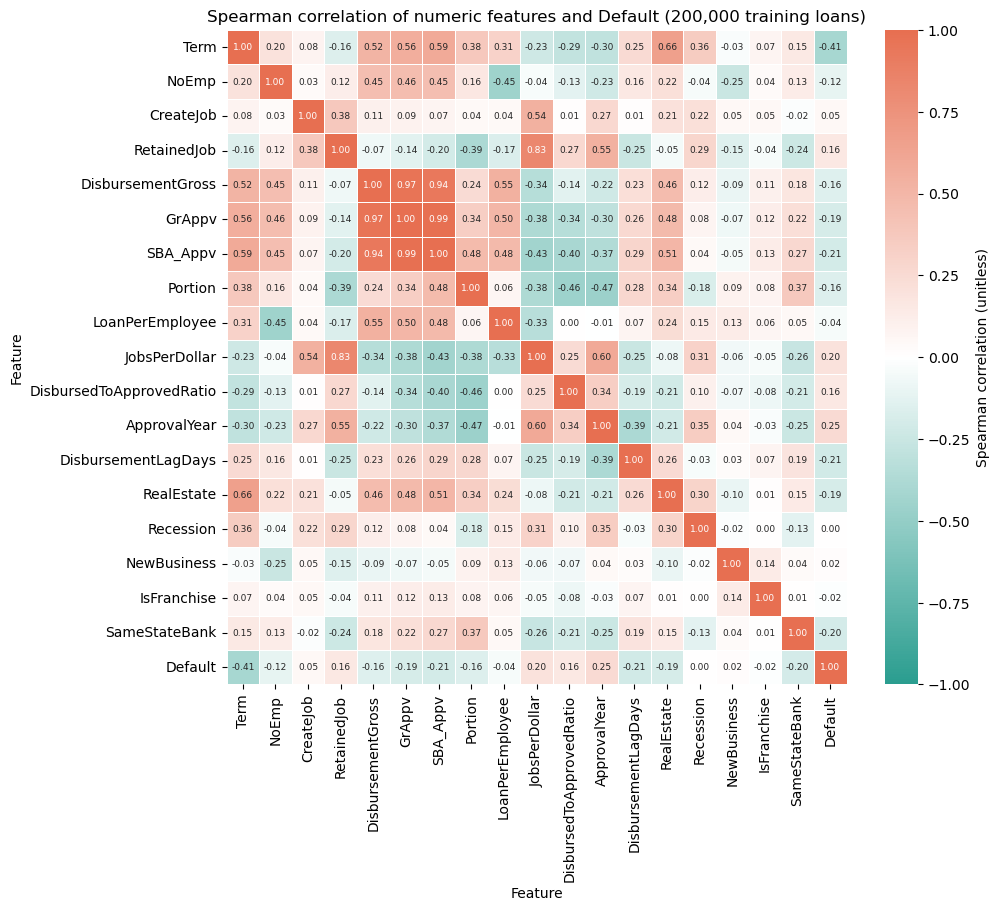

Correlation with Default:
Term                       -0.410
DisbursementLagDays        -0.214
SBA_Appv                   -0.206
SameStateBank              -0.196
GrAppv                     -0.189
RealEstate                 -0.189
Portion                    -0.158
DisbursementGross          -0.155
NoEmp                      -0.116
LoanPerEmployee            -0.043
IsFranchise                -0.015
Recession                   0.002
NewBusiness                 0.021
CreateJob                   0.054
RetainedJob                 0.157
DisbursedToApprovedRatio    0.158
JobsPerDollar               0.196
ApprovalYear                0.252


In [14]:
corr_cols = ["Term", "NoEmp", "CreateJob", "RetainedJob", "DisbursementGross", "GrAppv", "SBA_Appv",
             "Portion", "LoanPerEmployee", "JobsPerDollar", "DisbursedToApprovedRatio", "ApprovalYear",
             "DisbursementLagDays", "RealEstate", "Recession", "NewBusiness", "IsFranchise", "SameStateBank",
             config.TARGET]
corr_sample = train.sample(200_000, random_state=config.RANDOM_STATE)
corr = corr_sample[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8.5))
cmap = sns.blend_palette([P["teal"], "white", P["red"]], as_cmap=True)
sns.heatmap(corr, cmap=cmap, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", annot_kws={"size": 6.5},
            linewidths=0.4, cbar_kws={"label": "Spearman correlation (unitless)"}, ax=ax)
ax.set_title("Spearman correlation of numeric features and Default (200,000 training loans)")
ax.set_xlabel("Feature")
ax.set_ylabel("Feature")
save_fig(fig, "fig03_correlation_heatmap.png")
plt.show()
print("Correlation with Default:")
print(corr[config.TARGET].drop(config.TARGET).sort_values().round(3).to_string())

Term has the strongest rank correlation with Default (-0.41), followed by ApprovalYear (+0.25), DisbursementLagDays (-0.21), JobsPerDollar (+0.20) and SameStateBank (-0.20). The amount columns DisbursementGross, GrAppv and SBA_Appv are almost perfectly correlated with each other, which is why the final feature set keeps one amount (`LogDisbursement`) plus the two ratios built from the others (`Portion`, `DisbursedToApprovedRatio`). Recession has a correlation of almost zero with Default, which matches the cancelling effect seen in section 4.9.

### 4.12 Interactions: term with guaranteed portion, and sector with business age

A single feature can hide very different groups. The first heatmap crosses term and guaranteed share, the second crosses sector and business age.

Saved docs/figures/fig03_interaction_term_portion.png


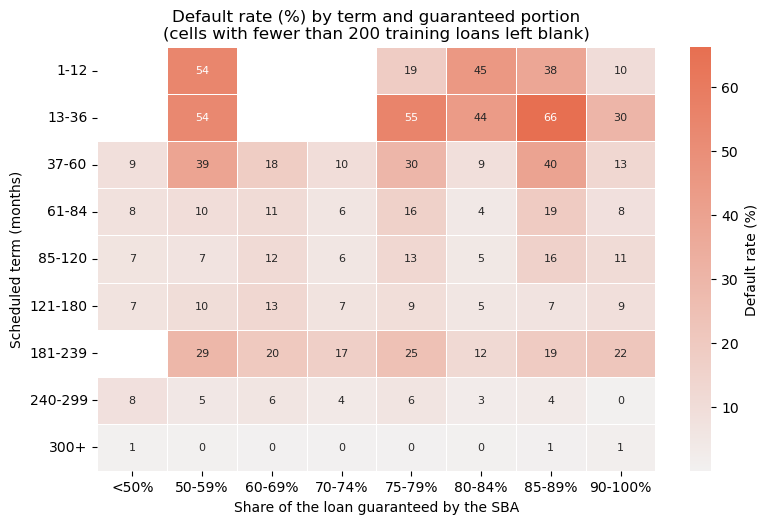

PortionBand,<50%,50-59%,60-69%,70-74%,75-79%,80-84%,85-89%,90-100%
TermBand,,,,,,,,
1-12,NaN,54.300,NaN,NaN,18.500,45.100,37.800,10.300
13-36,NaN,53.500,NaN,NaN,55.300,43.600,66.200,30.100
37-60,9.000,39.100,18.400,9.900,29.700,9.100,39.500,12.900
61-84,7.800,9.600,10.900,6.200,16.100,4.300,19.300,8.300
85-120,6.700,6.800,11.600,5.600,12.700,4.600,16.000,11.000
121-180,7.200,10.000,13.200,7.100,9.500,5.500,6.800,8.600
181-239,NaN,29.300,20.200,17.000,24.600,12.000,19.300,21.900
240-299,8.300,4.900,6.000,3.700,6.400,2.700,3.500,0.400
300+,0.500,0.400,0.300,0.000,0.100,0.400,0.600,1.400


In [15]:
inter = train.pivot_table(index="TermBand", columns="PortionBand", values=config.TARGET, aggfunc="mean", observed=True) * 100
inter_n = train.pivot_table(index="TermBand", columns="PortionBand", values=config.TARGET, aggfunc="size", observed=True)
inter = inter.where(inter_n >= 200)  # hide cells with too few loans to be reliable
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(inter, cmap=sns.light_palette(P["red"], as_cmap=True), annot=True, fmt=".0f", annot_kws={"size": 8},
            linewidths=0.4, cbar_kws={"label": "Default rate (%)"}, ax=ax)
ax.set_xlabel("Share of the loan guaranteed by the SBA")
ax.set_ylabel("Scheduled term (months)")
ax.set_title("Default rate (%) by term and guaranteed portion\n(cells with fewer than 200 training loans left blank)")
save_fig(fig, "fig03_interaction_term_portion.png")
plt.show()
inter.round(1)

The heatmap shows that term and guarantee interact: short loans (13 to 36 months) default at 53 to 66% when the guarantee is 50%, 75% or 85%, but long real-estate loans stay below 9% whatever the guarantee. Within the 61 to 84 month band alone the rate moves from 4.3% (80 to 84% guarantee) to 19.3% (85 to 89%), so neither feature alone describes the risk of a loan, which supports using a model that can combine them.

Saved docs/figures/fig03_interaction_sector_new_business.png


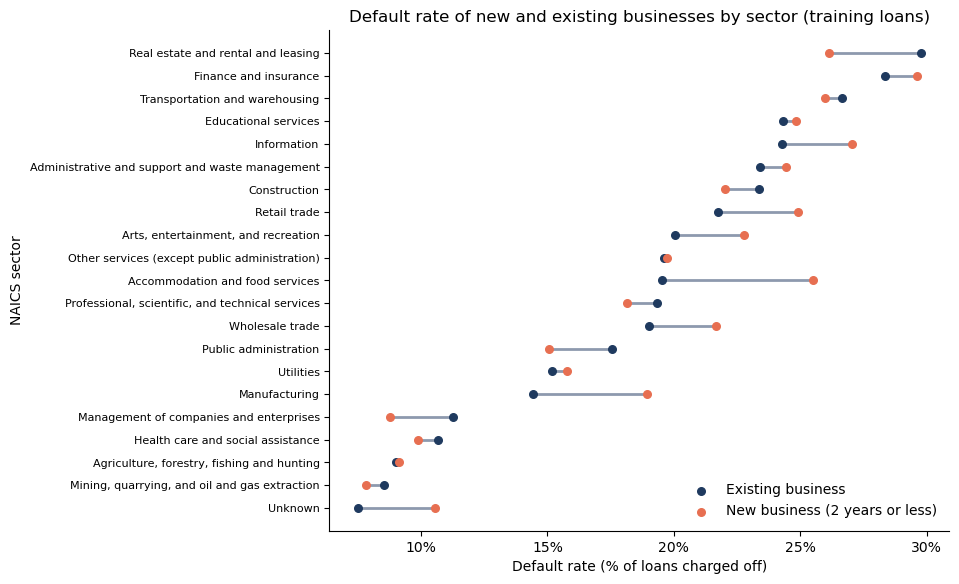

NewExist,Existing,New,gap_pp
Sector,,,
Real estate and rental and leasing,29.800,26.100,-3.600
Management of companies and enterprises,11.300,8.800,-2.500
Public administration,17.500,15.100,-2.500
Construction,23.400,22.000,-1.300
"Professional, scientific, and technical services",19.300,18.100,-1.200
Health care and social assistance,10.700,9.900,-0.800
"Mining, quarrying, and oil and gas extraction",8.500,7.800,-0.700
Transportation and warehousing,26.600,26.000,-0.700
"Agriculture, forestry, fishing and hunting",9.000,9.100,0.100


In [16]:
sec_new = train[train["NewExist"] != "Unknown"].pivot_table(
    index="Sector", columns="NewExist", values=config.TARGET, aggfunc="mean", observed=True) * 100
sec_new["gap_pp"] = sec_new["New"] - sec_new["Existing"]
sec_new = sec_new.sort_values("Existing")
fig, ax = plt.subplots(figsize=(8, 6.5))
y_pos = np.arange(len(sec_new))
ax.hlines(y_pos, sec_new["Existing"], sec_new["New"], color=P["grey"], lw=2)
ax.scatter(sec_new["Existing"], y_pos, color=P["navy"], s=30, label="Existing business", zorder=3)
ax.scatter(sec_new["New"], y_pos, color=P["red"], s=30, label="New business (2 years or less)", zorder=3)
ax.set_yticks(y_pos, sec_new.index, fontsize=8)
ax.set_xlabel("Default rate (% of loans charged off)")
ax.set_ylabel("NAICS sector")
ax.set_title("Default rate of new and existing businesses by sector (training loans)")
pct_axis(ax, "x")
ax.legend(frameon=False, loc="lower right")
save_fig(fig, "fig03_interaction_sector_new_business.png")
plt.show()
sec_new.sort_values("gap_pp").round(1)

Being a new business matters only in some industries. In accommodation and food services new businesses default at 25.5% against 19.5% for existing ones (6.0 points), and in manufacturing the gap is 4.5 points, whereas in real estate new businesses actually default less (26.1% against 29.8%). This explains why `NewBusiness` is weak on its own (section 6) and why it is still worth keeping for a tree model that can combine it with `Sector`.

### 4.13 Lenders

The data has 5,800 lending banks. Their loan books differ a lot in size, and we want to know whether bank size and a bank's own track record are related to default, which motivates the two bank features.

Saved docs/figures/fig03_default_rate_by_bank_size.png


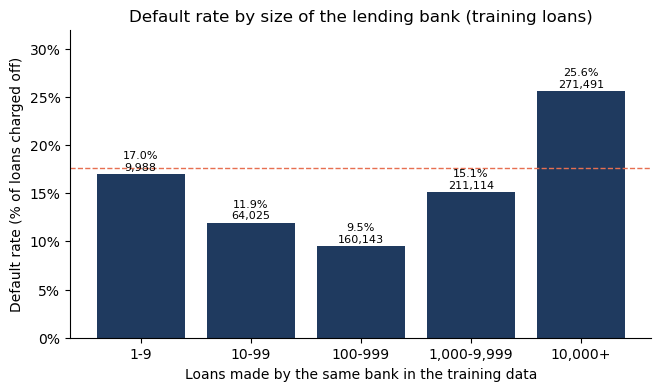

Banks: 5,597; with 1,000+ training loans: 81, holding 67.3% of loans
Default rate among those large banks ranges from 0.0% to 73.4%


,loans,default_rate_pct
BankSizeBand,,
1-9,9988,16.970
10-99,64025,11.936
100-999,160143,9.537
"1,000-9,999",211114,15.093
"10,000+",271491,25.571


In [17]:
bank_stats = train.groupby("Bank", observed=True)[config.TARGET].agg(loans="size", rate="mean")
bank_size_bins = [0, 10, 100, 1_000, 10_000, np.inf]
bank_size_labels = ["1-9", "10-99", "100-999", "1,000-9,999", "10,000+"]
train["BankSizeBand"] = pd.cut(train["Bank"].map(bank_stats["loans"]), bank_size_bins, labels=bank_size_labels, right=False)
bank_band = rate_table(train, "BankSizeBand")
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.bar(bank_band.index.astype(str), bank_band["default_rate_pct"], color=P["navy"])
for i, (r, n) in enumerate(zip(bank_band["default_rate_pct"], bank_band["loans"])):
    ax.text(i, r + 0.4, f"{r:.1f}%\n{n:,}", ha="center", fontsize=8)
ax.axhline(overall, color=P["red"], ls="--", lw=1)
ax.set_xlabel("Loans made by the same bank in the training data")
ax.set_ylabel("Default rate (% of loans charged off)")
ax.set_title("Default rate by size of the lending bank (training loans)")
pct_axis(ax)
ax.set_ylim(0, bank_band["default_rate_pct"].max() * 1.25)
save_fig(fig, "fig03_default_rate_by_bank_size.png")
plt.show()
big = bank_stats[bank_stats["loans"] >= 1000]
print(f"Banks: {len(bank_stats):,}; with 1,000+ training loans: {len(big)}, holding {big['loans'].sum() / len(train):.1%} of loans")
print(f"Default rate among those large banks ranges from {100 * big['rate'].min():.1f}% to {100 * big['rate'].max():.1f}%")
bank_band[["loans", "default_rate_pct"]]

Bank size has a U-shaped relationship with default: banks with 100 to 999 training loans have the lowest rate (9.5%), while the largest lenders with 10,000 or more loans have the highest (25.6%). The 81 banks with at least 1,000 training loans hold 67.3% of all loans, and their own default rates range from 0.0% to 73.4%, so the identity of the lender says a lot about underwriting standards and product mix. This is the motivation for `BankSize` and `BankDefaultRate`.

## 5. Feature engineering

### 5.1 The features and why we build them

All row-level features are created by `fe.build_features()` in section 2; the table lists each one with the reason. Formulas and names match the engineered-feature table in `docs/data_dictionary.md`.

| Feature | How it is built | Why |
|---|---|---|
| `Portion` | `SBA_Appv / GrAppv` | Sets the bank's own exposure on default and enters the cost matrix; section 4.5 shows it is also a risk signal |
| `RealEstate` | `Term >= 240` | Twenty-year loans are normally secured on property and default far less (section 4.4) |
| `Recession` | Scheduled life (disbursement to disbursement plus term) overlaps December 2007 to June 2009 | Loans exposed to the downturn; the effect depends on term (section 4.9) |
| `NewBusiness` | `NewExist == "New"` | Businesses of two years or less have no track record |
| `IsFranchise` | `FranchiseCode` not 0 or 1 | Franchises follow a tested business model |
| `SameStateBank` | `BankState == State` | Out-of-state lending is more remote from the borrower |
| `Sector` | First two NAICS digits mapped to the sector names in `config.NAICS_SECTORS`, 0 to Unknown | Industry risk differs by a factor of four (section 4.1) |
| `LoanPerEmployee` | `DisbursementGross / max(NoEmp, 1)` | Debt relative to the size of the business |
| `TermYears` | `Term / 12` | Term in a unit the credit officer reads directly |
| `ApprovalYear`, `ApprovalMonth` | From `ApprovalDate` | Lending cycle and season |
| `DisbursementLagDays` | `DisbursementDate - ApprovalDate` in days | Long delays may signal problems with the project |
| `DisbursementDateMissing` | 1 where no disbursement date exists | Records that the approval date was used as fallback |
| `JobsPerDollar` | `(CreateJob + RetainedJob) / DisbursementGross * 1e5` | Jobs supported per USD 100,000, the public policy side of the loan |
| `LogDisbursement` | `log(1 + DisbursementGross)` | Removes the right skew of amounts for the linear model |
| `DisbursedToApprovedRatio` | `DisbursementGross / GrAppv` | A loan drawn above or below its approval has changed since the decision |
| `RevLineCr` | Y, N (including raw 0), T, Unknown | Section 5.3 shows the raw code T must stay separate |
| `LowDoc`, `UrbanRural`, `NewExist`, `State`, `BankState` | Cleaned categorical levels, one-hot encoded | Unknown levels are kept as their own category because they carry signal (section 4.8) |
| `BankSize` | Training loans per bank | Lender scale and SBA experience |
| `BankDefaultRate` | Smoothed out-of-fold default rate per bank | Lender underwriting quality, learned from training data only |

**Missing disbursement dates.** 2,171 loans have no disbursement date. Rather than dropping them, `build_features()` uses the approval date as the start of the loan, which gives a lag of 0 days and a recession window measured from approval, and sets `DisbursementDateMissing = 1`. The check below confirms that every feature is complete.

In [18]:
miss = feats["DisbursementDateMissing"] == 1
print(f"Loans with missing DisbursementDate: {miss.sum():,}; default rate {feats.loc[miss, config.TARGET].mean():.2%}")
print("Lag on those rows:", feats.loc[miss, "DisbursementLagDays"].unique())
model_cols = fe.NUMERIC_FEATURES + fe.CATEGORICAL_FEATURES + [fe.BANK_COLUMN]
print("Missing values left in the model columns:", int(feats[model_cols].isna().sum().sum()))
feats.loc[miss, ["ApprovalDate", "DisbursementDate", "Term", "DisbursementLagDays", "Recession"]].head()

Loans with missing DisbursementDate: 2,171; default rate 15.06%
Lag on those rows: [0]


Missing values left in the model columns: 0


,ApprovalDate,DisbursementDate,Term,DisbursementLagDays,Recession
448,1998-11-27,NaT,60,0,0
1170,2003-10-09,NaT,13,0,0
1369,2003-12-12,NaT,84,0,1
1512,2004-03-16,NaT,60,0,1
1530,2004-03-19,NaT,84,0,1


All 2,171 loans without a disbursement date are kept, with a lag of 0 days and the flag set; they default at 15.1%, close to the average, so the fallback does not hide a high-risk group. After `build_features()` none of the model columns has a missing value; the median imputers in the preprocessor are there for app inputs.

### 5.2 Default rate for each engineered feature

For binary and categorical features we show every level; numeric features are cut into five equal-count bins (quintiles) on the training data. Categorical features with many levels (`Sector`, `State`) were already shown in section 4.

In [19]:
def feature_rate_table(data, col, q=5):
    """Default-rate table for one feature: levels, or quintiles for numeric columns."""
    s = data[col]
    if pd.api.types.is_numeric_dtype(s) and s.nunique() > 12:
        s = pd.qcut(s, q, duplicates="drop")
    t = data.groupby(s, observed=True)[config.TARGET].agg(loans="size", default_rate_pct="mean")
    t["default_rate_pct"] *= 100
    t.index = t.index.astype(str)
    return t


engineered = fe.ENGINEERED_NUMERIC + fe.ENGINEERED_BINARY + ["RevLineCr"]
rate_tables = pd.concat({c: feature_rate_table(train, c) for c in engineered}, names=["feature", "level"])
with pd.option_context("display.max_rows", 200):
    display(rate_tables.round(2))

loans  default_rate_pct
feature                  level                                                
Portion                  (0.049, 0.5]                 260702            26.400
                         (0.5, 0.75]                  157587            12.170
                         (0.75, 0.8]                   67599             7.880
                         (0.8, 0.85]                  107544            22.900
                         (0.85, 1.0]                  123329             6.420
TermYears                (0.0823, 5.0]                211109            38.310
                         (5.0, 7.0]                   232857            11.100
                         (7.0, 15.0]                  139868            10.500
                         (15.0, 47.417]               132927             3.370
LogDisbursement          (8.293000000000001, 10.463]  154699            25.520
                         (10.463, 11.165]             132006            21.170
                         (11.165, 11.813]             143842            18.000
                         (11.813, 12.612]             148085            13.390
                         (12.612, 16.253]             138129             9.230
LoanPerEmployee          (20.555, 7409.091]           143356            19.770
                         (7409.091, 15000.0]          152023            18.420
                         (15000.0, 26666.667]         135057            18.160
                         (26666.667, 55500.0]         142995            16.500
                         (55500.0, 5000000.0]         143330            14.960
JobsPerDollar            (-0.001, 3.34]               430057            12.130
                         (3.34, 10.44]                143353            23.770
                         (10.44, 6725.0]              143351            27.650
DisbursedToApprovedRatio (0.0093, 1.0]                592238            14.510
                         (1.0, 18.321]                124523            32.110
ApprovalYear             (1965.999, 1995.0]           150148             6.440
                         (1995.0, 2000.0]             150720             8.290
                         (2000.0, 2004.0]             174943            15.430
                         (2004.0, 2006.0]             120835            32.240
                         (2006.0, 2014.0]             120115            31.460
ApprovalMonth            1                             53658            17.690
                         2                             52835            18.170
                         3                             66592            17.820
                         4                             63896            17.060
                         5                             61716            17.330
                         6                             62407            17.610
                         7                             60907            16.840
                         8                             62848            17.970
                         9                             66218            16.390
                         10                            55442            18.290
                         11                            54490            18.200
                         12                            55752            17.750
DisbursementLagDays      (-3530.001, 25.0]            143387            29.610
                         (25.0, 45.0]                 147409            24.000
                         (45.0, 77.0]                 141641            15.620
                         (77.0, 144.0]                141588            10.580
                         (144.0, 9443.0]              142736             7.670
RealEstate               0                            595036            20.820
                         1                            121725             1.650
Recession                0                            271080            17.360
                         1

Most engineered features separate risk clearly. `DisbursedToApprovedRatio` is a good example of a feature built from two raw columns that adds a new idea: loans drawn above their approved amount default at 32.1% against 14.5% for the rest, and 91% of them are revolving lines, whose drawn balance can exceed the approved limit. `DisbursementLagDays` falls from 29.6% for loans paid out within 25 days to 7.7% for loans paid out after more than 144 days, which we read as a sign of the fast-approval products of the 2000s rather than of slow disbursement being safe. `ApprovalMonth` (16.4% to 18.3%), `IsFranchise` and `NewBusiness` show little spread on their own.

### 5.3 Does the raw RevLineCr code T add signal?

Cleaning mapped the raw code `T` to `Y` because the two groups look alike on amount, term, guarantee share and LowDoc use (notebook 01). On default, though, section 4.8 shows `T` at a much higher rate than `Y`. That could simply be because `T` loans were concentrated in the bad years. We therefore compare `T` and `Y` within each approval year; if the gap disappears, the code is only a proxy for time and should be dropped.

In [20]:
ty = train[train["RevLineCr"].isin(["Y", "T"]) & train["ApprovalYear"].between(1998, 2012)]
within_year = ty.pivot_table(index="ApprovalYear", columns="RevLineCr", values=config.TARGET,
                             aggfunc=["mean", "size"], observed=True)
within_year = pd.DataFrame({
    "T_loans": within_year[("size", "T")], "T_rate_pct": 100 * within_year[("mean", "T")],
    "Y_loans": within_year[("size", "Y")], "Y_rate_pct": 100 * within_year[("mean", "Y")],
})
within_year["gap_pp"] = within_year["T_rate_pct"] - within_year["Y_rate_pct"]
years_t_higher = int((within_year["gap_pp"] > 0).sum())
# Weighted average gap, using the number of T loans in each year as weight
weighted_gap = np.average(within_year["gap_pp"], weights=within_year["T_loans"])
print(f"T defaults more than Y in {years_t_higher} of {len(within_year)} years; "
      f"gap weighted by T loans: {weighted_gap:.1f} percentage points")
within_year.round(1)

T defaults more than Y in 10 of 15 years; gap weighted by T loans: 19.6 percentage points


,T_loans,T_rate_pct,Y_loans,Y_rate_pct,gap_pp
ApprovalYear,,,,,
1998,158,0.600,2098,8.000,-7.400
1999,226,1.800,2764,8.400,-6.600
2000,271,4.400,4245,10.900,-6.500
2001,383,7.000,5529,11.400,-4.400
2002,849,21.700,9223,13.700,8.000
2003,1551,35.300,16479,14.500,20.800
2004,1777,51.600,20056,17.500,34.100
2005,1948,57.100,21261,26.200,30.900
2006,2110,63.300,28291,37.500,25.800


The gap between T and Y is not just a time effect: in the years when most T loans were made (2002 to 2007) T defaults 8 to 34 percentage points more than Y within the same approval year, and the gap weighted by the number of T loans is 19.6 points. The direction reverses for the few T loans of 1998 to 2001 and is small after 2008, so the code most likely marks a specific product or reporting practice of the 2000s. On this evidence we keep `T` as its own level of the `RevLineCr` feature (levels Y, N, T, Unknown); `RevLineCr_raw` itself, with its 16 one-off codes, is not used.

The ablation in section 6.3 adds a model-based test: the final feature set with `RevLineCr` as cleaned (T inside Y) against the same set with T as its own level.

### 5.4 Bank encodings fitted on training data only

`BankSize` counts a bank's training loans. `BankDefaultRate` is a target encoding: the bank's default rate, pulled towards the overall rate when the bank has few loans,

$$\text{rate}_b = \frac{\text{defaults}_b + m \cdot \bar{y}}{\text{loans}_b + m}, \quad m = 20.$$

The leakage risk is that a loan's own outcome enters its own feature. If we computed bank rates on the full table, test loans would be encoded with rates that include their own labels, and the test score would be too optimistic. Even within the training data, encoding a loan with a rate that includes its own label lets the model partly read the answer, which matters most for small banks. `fe.BankEncoder` avoids both problems: `fit_transform` on the training data encodes each loan with statistics from the other four of five folds (out-of-fold), and `transform` on test data or an app input uses the rates learned from all training loans, with unseen banks set to the overall training rate. Because it is a scikit-learn transformer inside the pipeline, cross-validation in notebooks 04 and 05 refits it inside every fold automatically.

In [21]:
bank_enc = fe.BankEncoder()
bank_train = bank_enc.fit_transform(train[[fe.BANK_COLUMN]], y_train)
bank_test = bank_enc.transform(feats.loc[X_test_all.index, [fe.BANK_COLUMN]])
train["BankSize"], train["BankDefaultRate"] = bank_train[:, 0], bank_train[:, 1]

unseen = ~feats.loc[X_test_all.index, fe.BANK_COLUMN].isin(bank_enc.size_map_.index)
print(f"Banks learned from training data: {len(bank_enc.size_map_):,}; global rate {bank_enc.global_rate_:.4f}")
print(f"Test loans from banks not seen in training: {unseen.sum():,} (encoded with the global rate)")

# How much the in-sample rate would flatter the feature compared with the out-of-fold rate
in_sample = bank_enc.transform(train[[fe.BANK_COLUMN]])[:, 1]
print(f"Univariate ROC-AUC of BankDefaultRate on training loans: in-sample {roc_auc_score(y_train, in_sample):.4f}, "
      f"out-of-fold {roc_auc_score(y_train, train['BankDefaultRate']):.4f}")
print(f"Univariate ROC-AUC of BankDefaultRate on test loans (fitted on train): {roc_auc_score(y_test, bank_test[:, 1]):.4f}")
feature_rate_table(train, "BankDefaultRate")

Banks learned from training data: 5,597; global rate 0.1756
Test loans from banks not seen in training: 239 (encoded with the global rate)


Univariate ROC-AUC of BankDefaultRate on training loans: in-sample 0.7288, out-of-fold 0.7210
Univariate ROC-AUC of BankDefaultRate on test loans (fitted on train): 0.7234


,loans,default_rate_pct
BankDefaultRate,,
"(0.00041, 0.0887]",143353,4.065
"(0.0887, 0.135]",144266,10.897
"(0.135, 0.176]",143602,14.799
"(0.176, 0.275]",144826,22.736
"(0.275, 0.831]",140714,35.654


The out-of-fold encoding gives a training ROC-AUC (0.7210) slightly below the in-sample version (0.7288) and close to the test ROC-AUC (0.7234), which is the behaviour we want: the training value is not inflated by the loan's own label, so the model will not learn to trust the feature more than it deserves on new loans. Only 239 test loans come from banks the encoder has never seen, and they receive the global rate of 17.56%. Across quintiles, BankDefaultRate separates loans from 4.1% to 35.7% default.

## 6. Testing the value of the features

### 6.1 Univariate spread and ROC-AUC

For each feature we report the spread of default rates across its levels or quintiles (highest minus lowest, levels with at least 1% of loans) and its univariate ROC-AUC on the training data. For categorical features the ROC-AUC uses each level's training default rate as the score, so it is an in-sample upper bound.

In [22]:
all_features = fe.NUMERIC_FEATURES + fe.CATEGORICAL_FEATURES + fe.BANK_FEATURES
engineered_set = set(fe.ENGINEERED_NUMERIC + fe.ENGINEERED_BINARY + ["Sector", "RevLineCr"] + fe.BANK_FEATURES)


def univariate_score(data, col):
    """Default-rate spread (pp) and univariate ROC-AUC for one feature."""
    t = feature_rate_table(data, col)
    t = t[t["loans"] >= 0.01 * len(data)]
    spread = t["default_rate_pct"].max() - t["default_rate_pct"].min()
    s = data[col]
    if not pd.api.types.is_numeric_dtype(s):
        s = s.map(data.groupby(col, observed=True)[config.TARGET].mean())
    auc = roc_auc_score(data[config.TARGET], s)
    return spread, max(auc, 1 - auc)


rows = []
for col in all_features:
    spread, auc = univariate_score(train, col)
    rows.append({"feature": col, "kind": "categorical" if col in fe.CATEGORICAL_FEATURES else "numeric",
                 "engineered": col in engineered_set, "rate_spread_pp": spread, "univariate_auc": auc})
value_tests = pd.DataFrame(rows).set_index("feature")
value_tests.sort_values("univariate_auc", ascending=False).round(3)

,kind,engineered,rate_spread_pp,univariate_auc
feature,,,,
TermYears,numeric,True,34.945,0.806
BankDefaultRate,numeric,True,31.588,0.721
ApprovalYear,numeric,True,25.807,0.692
DisbursementLagDays,numeric,True,21.937,0.664
BankState,categorical,False,31.481,0.646
JobsPerDollar,numeric,True,15.523,0.642
UrbanRural,categorical,False,17.316,0.642
SameStateBank,numeric,True,14.857,0.628
Sector,categorical,True,20.425,0.620


### 6.2 Mutual information with the target

Mutual information measures how much knowing a feature reduces uncertainty about default, and it also picks up non-monotonic patterns such as the U shape in term. We estimate it on a stratified sample of 100,000 training loans to keep the run time short; categorical features are passed as integer codes and marked as discrete, as are the 0/1 indicators and the approval year and month.

Mutual information computed in 7 s


Saved docs/figures/fig03_mutual_information.png


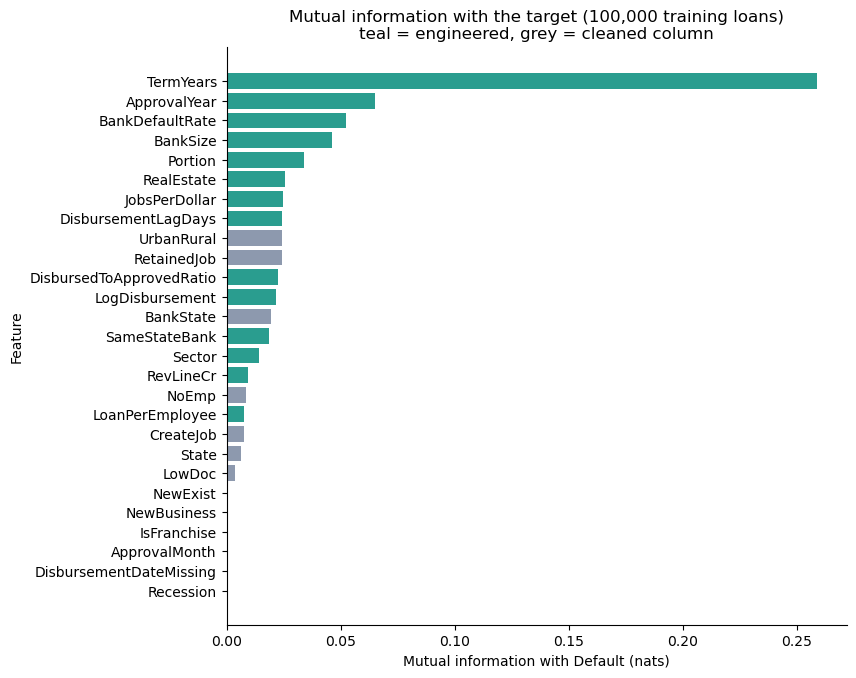

,kind,engineered,rate_spread_pp,univariate_auc,mutual_info,mi_rank
feature,,,,,,
TermYears,numeric,True,34.945,0.806,0.259,1
ApprovalYear,numeric,True,25.807,0.692,0.065,2
BankDefaultRate,numeric,True,31.588,0.721,0.053,3
BankSize,numeric,True,18.574,0.612,0.046,4
Portion,numeric,True,19.982,0.618,0.034,5
RealEstate,numeric,True,19.168,0.593,0.026,6
JobsPerDollar,numeric,True,15.523,0.642,0.025,7
DisbursementLagDays,numeric,True,21.937,0.664,0.024,8
UrbanRural,categorical,False,17.316,0.641,0.024,9


In [23]:
t0 = time.time()
mi_sample, _ = train_test_split(train, train_size=100_000, stratify=train[config.TARGET], random_state=config.RANDOM_STATE)
mi_X = mi_sample[all_features].copy()
for col in fe.CATEGORICAL_FEATURES:
    mi_X[col] = mi_X[col].astype("category").cat.codes
discrete = [c in fe.CATEGORICAL_FEATURES or c in fe.ENGINEERED_BINARY or c in ("ApprovalYear", "ApprovalMonth")
            for c in all_features]
mi = mutual_info_classif(mi_X, mi_sample[config.TARGET], discrete_features=np.array(discrete),
                         random_state=config.RANDOM_STATE)
value_tests["mutual_info"] = pd.Series(mi, index=all_features)
value_tests["mi_rank"] = value_tests["mutual_info"].rank(ascending=False).astype(int)
print(f"Mutual information computed in {time.time() - t0:.0f} s")

mi_sorted = value_tests.sort_values("mutual_info")
fig, ax = plt.subplots(figsize=(8, 7.5))
ax.barh(mi_sorted.index, mi_sorted["mutual_info"],
        color=[P["teal"] if e else P["grey"] for e in mi_sorted["engineered"]])
ax.set_xlabel("Mutual information with Default (nats)")
ax.set_ylabel("Feature")
ax.set_title("Mutual information with the target (100,000 training loans)\nteal = engineered, grey = cleaned column")
save_fig(fig, "fig03_mutual_information.png")
plt.show()
value_tests.sort_values("mutual_info", ascending=False).head(10).round(4)

Term (as `TermYears`) carries by far the most information (0.259 nats, four times the next feature), followed by ApprovalYear, the two bank encodings, Portion and RealEstate. Eight of the ten most informative features are engineered, although `TermYears` and `ApprovalYear` are simple re-expressions of the raw `Term` and approval date. Recession, ApprovalMonth, IsFranchise, NewBusiness and DisbursementDateMissing have mutual information close to zero on their own; we keep them because the interaction plots show that some (Recession, NewBusiness) matter within subgroups, and the ablation below checks that the feature set as a whole helps.

### 6.3 Ablation: raw cleaned columns against raw plus engineered features

The decisive test is whether a model does better with the engineered features. We train LightGBM with default settings on the training split and score the held-out test split from `md.split_data()`. Every model uses the same preprocessor from `md.build_preprocessor()`, so only the columns differ. This is a quick check on one split, not model selection (that is notebook 04), and it is the only time this notebook touches the test labels.

| Model | Columns |
|---|---|
| A. Raw cleaned columns | `Term`, `NoEmp`, `CreateJob`, `RetainedJob`, `DisbursementGross`, `GrAppv`, `SBA_Appv`, `NAICS` and `FranchiseCode` as numbers, `ApprovalFY`, and the cleaned `RevLineCr`, `LowDoc`, `UrbanRural`, `NewExist`, `State`, `BankState` |
| B. Raw plus engineered | A plus every engineered feature and the two bank encodings |
| C. Final feature set | `FEATURE_COLUMNS`: engineered features replace the raw columns they were derived from |
| D. C with RevLineCr as cleaned | C, but T merged into Y as in notebook 02 |
| E. C without bank encodings | C without `BankSize` and `BankDefaultRate` |

In [24]:
t_ablation = time.time()
abl = feats.copy()
abl["RevLineCrClean"] = clean["RevLineCr"].astype(str)  # cleaned code, T inside Y
raw_cat = ["RevLineCrClean", "LowDoc", "UrbanRural", "NewExist", "State", "BankState"]
new_cols = fe.ENGINEERED_NUMERIC + fe.ENGINEERED_BINARY
final_cat = fe.CATEGORICAL_FEATURES
designs = {
    "A. Raw cleaned columns": (fe.RAW_BASELINE_NUMERIC, raw_cat, None),
    "B. Raw plus engineered": (fe.RAW_BASELINE_NUMERIC + new_cols, raw_cat + ["Sector", "RevLineCr"], fe.BANK_COLUMN),
    "C. Final feature set": (fe.NUMERIC_FEATURES, final_cat, fe.BANK_COLUMN),
    "D. C with RevLineCr as cleaned": (fe.NUMERIC_FEATURES, [c if c != "RevLineCr" else "RevLineCrClean" for c in final_cat], fe.BANK_COLUMN),
    "E. C without bank encodings": (fe.NUMERIC_FEATURES, final_cat, None),
}
needed = sorted({c for num, cat, bank in designs.values() for c in num + cat + ([bank] if bank else [])})
Xa_train, Xa_test, ya_train, ya_test = md.split_data(abl, feature_columns=needed)
assert Xa_test.index.equals(X_test_all.index)

results, test_preds = [], {}
for name, (num, cat, bank) in designs.items():
    t0 = time.time()
    pipe = Pipeline([
        ("prep", md.build_preprocessor(num, cat, bank)),
        ("model", LGBMClassifier(n_jobs=4, random_state=config.RANDOM_STATE, verbose=-1)),
    ])
    pipe.fit(Xa_train, ya_train)
    p = pipe.predict_proba(Xa_test)[:, 1]
    test_preds[name] = p
    results.append({"model": name, "n_input_columns": len(num) + len(cat) + (1 if bank else 0),
                    "roc_auc": roc_auc_score(ya_test, p), "pr_auc": average_precision_score(ya_test, p),
                    "fit_seconds": time.time() - t0})
ablation = pd.DataFrame(results).set_index("model")
base = ablation.loc["A. Raw cleaned columns"]
ablation["roc_auc_gain"] = ablation["roc_auc"] - base["roc_auc"]
ablation["pr_auc_gain"] = ablation["pr_auc"] - base["pr_auc"]
print(f"Ablation finished in {time.time() - t_ablation:.0f} s")
ablation.round(4)

Ablation finished in 82 s


,n_input_columns,roc_auc,pr_auc,fit_seconds,roc_auc_gain,pr_auc_gain
model,,,,,,
A. Raw cleaned columns,16,0.978,0.914,10.057,0.000,0.000
B. Raw plus engineered,34,0.981,0.925,20.644,0.003,0.011
C. Final feature set,26,0.981,0.923,16.466,0.003,0.009
D. C with RevLineCr as cleaned,26,0.980,0.923,15.565,0.003,0.009
E. C without bank encodings,25,0.979,0.916,17.870,0.001,0.002


Saved docs/figures/fig03_feature_ablation.png


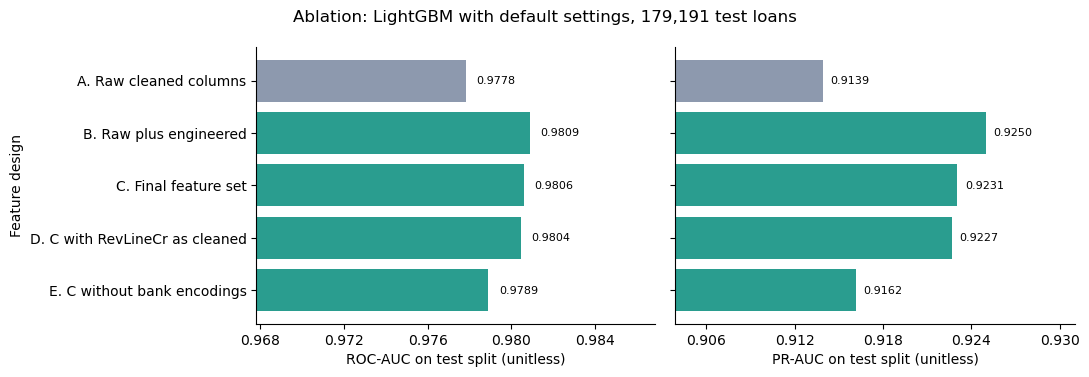

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
names = ablation.index[::-1]
for ax, metric, label in [(axes[0], "roc_auc", "ROC-AUC on test split"), (axes[1], "pr_auc", "PR-AUC on test split")]:
    vals = ablation.loc[names, metric]
    ax.barh(names, vals, color=[P["grey"] if n.startswith("A") else P["teal"] for n in names])
    for i, v in enumerate(vals):
        ax.text(v + 0.0005, i, f"{v:.4f}", va="center", fontsize=8)
    lo = ablation[metric].min()
    ax.set_xlim(lo - 0.01, ablation[metric].max() + 0.006)
    ax.set_xlabel(f"{label} (unitless)")
    ax.xaxis.set_major_locator(mtick.MaxNLocator(5))
axes[0].set_ylabel("Feature design")
fig.suptitle("Ablation: LightGBM with default settings, 179,191 test loans")
fig.tight_layout()
save_fig(fig, "fig03_feature_ablation.png")
plt.show()

The raw cleaned columns alone already give LightGBM a test ROC-AUC of 0.9778 and PR-AUC of 0.9139, largely because Term and ApprovalFY are so strong. Adding the engineered features raises this to 0.9809 and 0.9250 (model B), and the leaner final feature set C reaches 0.9806 and 0.9231 with 26 instead of 34 input columns. The gain in PR-AUC (0.9 to 1.1 points) is the more relevant one for the bank, because it measures how well the model finds the minority of defaulting loans. Removing the bank encodings (E) gives back most of the gain (PR-AUC 0.9162), so `BankSize` and `BankDefaultRate` are the most valuable additions. Keeping RevLineCr code T separate (C against D) adds only 0.0002 ROC-AUC and 0.0004 PR-AUC, because the bank and term features already capture much of what T signals; we keep it because it is free and the within-year evidence is clear. The very high scores of even the raw model should be read with the Term and censoring caveats from sections 4.2 and 4.4 in mind.

### 6.4 Save the feature value tests

The per-feature results (spread, univariate ROC-AUC, mutual information) go to `docs/feature_value_tests.csv` and the ablation to `docs/feature_ablation.csv`, so the report quotes them exactly.

In [26]:
value_tests_out = value_tests.sort_values("mutual_info", ascending=False).round(5)
value_tests_out.to_csv(config.DOCS_DIR / "feature_value_tests.csv")
ablation.round(5).to_csv(config.DOCS_DIR / "feature_ablation.csv")
print("Saved docs/feature_value_tests.csv and docs/feature_ablation.csv")
value_tests_out

Saved docs/feature_value_tests.csv and docs/feature_ablation.csv


,kind,engineered,rate_spread_pp,univariate_auc,mutual_info,mi_rank
feature,,,,,,
TermYears,numeric,True,34.945,0.806,0.259,1
ApprovalYear,numeric,True,25.807,0.692,0.065,2
BankDefaultRate,numeric,True,31.588,0.721,0.053,3
BankSize,numeric,True,18.574,0.611,0.046,4
Portion,numeric,True,19.982,0.617,0.034,5
RealEstate,numeric,True,19.168,0.593,0.026,6
JobsPerDollar,numeric,True,15.523,0.642,0.025,7
DisbursementLagDays,numeric,True,21.937,0.664,0.024,8
UrbanRural,categorical,False,17.316,0.642,0.024,9


## 7. Save the feature table and the feature schema

`loans_features.parquet` holds, for every labelled loan, the identifier, the target, `ApprovalFY` and `ApprovalDate` (for the temporal validation in notebook 05), the amounts needed by the cost matrix, the raw columns of the ablation baseline and all model input columns. Leakage columns, audit flags, `Name`, `City` and `Zip` are left out, so later notebooks cannot use them by mistake.

In [27]:
keep = (["LoanNr_ChkDgt", config.TARGET, "ApprovalFY", "ApprovalDate", "DisbursementDate", "Term", "DisbursementGross",
         "GrAppv", "SBA_Appv", "NAICS", "FranchiseCode"] + fe.FEATURE_COLUMNS)
keep = list(dict.fromkeys(keep))  # drop repeated names, keep order
out = feats[keep].copy()
for col in fe.CATEGORICAL_FEATURES + [fe.BANK_COLUMN]:
    out[col] = out[col].astype("category")
assert not set(out.columns) & set(fe.EXCLUDED_COLUMNS) - {"LoanNr_ChkDgt"}
out.to_parquet(config.FEATURES_DATA_PATH, index=False)
size_mb = config.FEATURES_DATA_PATH.stat().st_size / 1e6
print(f"Saved {config.FEATURES_DATA_PATH.relative_to(config.PROJECT_ROOT)}: {out.shape[0]:,} rows, {out.shape[1]} columns, {size_mb:.1f} MB")
out.dtypes.astype(str).to_frame("dtype").T

Saved data/processed/loans_features.parquet: 895,952 rows, 37 columns, 38.0 MB


,LoanNr_ChkDgt,Default,ApprovalFY,ApprovalDate,DisbursementDate,Term,DisbursementGross,GrAppv,SBA_Appv,NAICS,FranchiseCode,NoEmp,CreateJob,RetainedJob,Portion,TermYears,LogDisbursement,LoanPerEmployee,JobsPerDollar,DisbursedToApprovedRatio,ApprovalYear,ApprovalMonth,DisbursementLagDays,RealEstate,Recession,NewBusiness,IsFranchise,SameStateBank,DisbursementDateMissing,Sector,RevLineCr,LowDoc,UrbanRural,NewExist,State,BankState,Bank
dtype,int64,int8,int16,datetime64[ns],datetime64[ns],int32,float64,float64,float64,int32,int32,int32,int32,int32,float64,float64,float64,float64,float64,float64,int16,int8,int32,int8,int8,int8,int8,int8,int8,category,category,category,category,category,category,category,category


The schema in `models/feature_schema.json` tells the Streamlit app what each model input looks like on the training data: its type, the allowed categories or the observed numeric range (minimum, maximum and the 1st and 99th percentiles), a sensible default for the form (median or most common value), a label and a help text. It also lists the raw fields the form collects, because the app runs `build_features()` on those exactly as we did here.

In [28]:
def describe_feature(col, values, role):
    """Schema entry for one column, using training data only."""
    label, help_text = fe.FEATURE_INFO.get(col, (col, ""))
    entry = {"name": col, "role": role, "label": label, "help": help_text}
    if role in ("categorical", "bank") or not pd.api.types.is_numeric_dtype(values):
        counts = values.astype(str).value_counts()
        entry.update(dtype="category", allowed=counts.index.tolist(), default=str(counts.index[0]))
        if role == "bank":
            entry["note"] = "Banks not in this list are encoded with the overall training default rate."
    else:
        is_int = pd.api.types.is_integer_dtype(values) or role == "binary"
        q = values.quantile([0.01, 0.5, 0.99])
        entry.update(
            dtype="int" if is_int else "float",
            min=float(values.min()), max=float(values.max()),
            p01=float(q.loc[0.01]), p99=float(q.loc[0.99]),
            default=int(values.mode().iloc[0]) if role == "binary" else (int(round(q.loc[0.5])) if is_int else float(q.loc[0.5])),
        )
        if role == "binary":
            entry["allowed"] = [0, 1]
    return entry


schema_features = []
for col in fe.NUMERIC_FEATURES:
    role = "binary" if col in fe.ENGINEERED_BINARY else "numeric"
    schema_features.append(describe_feature(col, train[col], role))
for col in fe.CATEGORICAL_FEATURES:
    schema_features.append(describe_feature(col, train[col], "categorical"))
schema_features.append(describe_feature(fe.BANK_COLUMN, train[fe.BANK_COLUMN], "bank"))
for col in fe.BANK_FEATURES:  # produced inside the pipeline, listed for the explanation pages
    e = describe_feature(col, train[col], "numeric")
    e["role"] = "derived_in_pipeline"
    schema_features.append(e)

raw_form_fields = ["Term", "NoEmp", "CreateJob", "RetainedJob", "DisbursementGross", "GrAppv", "SBA_Appv",
                   "FranchiseCode", "NAICS"]
raw_info = {
    "Term": ("Term (months)", "Scheduled term of the loan in months."),
    "DisbursementGross": ("Amount disbursed (USD)", "Amount paid out to the borrower."),
    "GrAppv": ("Gross amount approved (USD)", "Loan amount approved by the bank."),
    "SBA_Appv": ("Guaranteed amount (USD)", "Part of the approved amount covered by the guarantee; cannot exceed the approved amount."),
    "FranchiseCode": ("Franchise code", "0 or 1 means no franchise; any other value is a franchise code."),
    "NAICS": ("NAICS industry code", "Six-digit industry code; 0 if unknown."),
}
raw_fields = []
for col in raw_form_fields:
    e = describe_feature(col, train[col], "numeric")
    e["label"], e["help"] = raw_info.get(col, fe.FEATURE_INFO.get(col, (col, "")))
    raw_fields.append(e)
for col in ["ApprovalDate", "DisbursementDate"]:
    d = train[col].dropna()
    raw_fields.append({"name": col, "role": "raw_input", "dtype": "date", "min": str(d.min().date()),
                       "max": str(d.max().date()), "label": col.replace("Date", " date"),
                       "help": "Disbursement date may be left empty; the approval date is then used." if col == "DisbursementDate" else "Date the guarantee was approved."})

schema = {
    "description": "Model input schema for CreditLens, built from the training split in notebooks/03_eda_feature_engineering.ipynb",
    "target": config.TARGET,
    "id_column": md.ID_COLUMN,
    "n_training_loans": int(len(train)),
    "training_default_rate": float(y_train.mean()),
    "model_input_columns": fe.FEATURE_COLUMNS,
    "numeric_features": fe.NUMERIC_FEATURES,
    "categorical_features": fe.CATEGORICAL_FEATURES,
    "bank_column": fe.BANK_COLUMN,
    "bank_features": fe.BANK_FEATURES,
    "excluded_columns": fe.EXCLUDED_COLUMNS,
    "features": schema_features,
    "raw_form_fields": raw_fields,
}
with open(config.FEATURE_SCHEMA_PATH, "w") as f:
    json.dump(schema, f, indent=2)
print(f"Saved {config.FEATURE_SCHEMA_PATH.relative_to(config.PROJECT_ROOT)} with {len(schema_features)} feature entries "
      f"and {len(raw_fields)} raw form fields ({config.FEATURE_SCHEMA_PATH.stat().st_size / 1e3:.0f} kB)")
pd.DataFrame(schema_features)[["name", "role", "dtype", "default", "label"]]

Saved models/feature_schema.json with 28 feature entries and 11 raw form fields (205 kB)


,name,role,dtype,default,label
0,NoEmp,numeric,int,4,Number of employees
1,CreateJob,numeric,int,0,Jobs to be created
2,RetainedJob,numeric,int,1,Jobs retained
3,Portion,numeric,float,0.750,Guaranteed share
4,TermYears,numeric,float,7.000,Term (years)
5,LogDisbursement,numeric,float,11.513,Log of disbursed amount
6,LoanPerEmployee,numeric,float,"20,000.000",Loan per employee (USD)
7,JobsPerDollar,numeric,float,1.550,"Jobs per USD 100,000"
8,DisbursedToApprovedRatio,numeric,float,1.000,Disbursed to approved ratio
9,ApprovalYear,numeric,int,2002,Approval year


## 8. Key findings for the report

The findings below are written to `docs/eda_findings.md`. Every number is taken from the tables computed above, so the report and this notebook cannot drift apart.

In [29]:
# Numbers used in the findings, all taken from the tables above
sec_hi, sec_lo = sector["default_rate_pct"].idxmax(), sector.drop(config.UNKNOWN_SECTOR)["default_rate_pct"].idxmin()
yr = year["default_rate_pct"]
t_short = term.loc["13-36", "default_rate_pct"]
t_re = 100 * train.loc[train["RealEstate"] == 1, config.TARGET].mean()
t_nre = 100 * train.loc[train["RealEstate"] == 0, config.TARGET].mean()
same = profile["SameStateBank"]["default_rate_pct"]
rec_short = 100 * train.loc[(train["Recession"] == 1) & (train["Term"] <= 60), config.TARGET].mean()
norec_short = 100 * train.loc[(train["Recession"] == 0) & (train["Term"] <= 60), config.TARGET].mean()
abl_a, abl_c, abl_d, abl_e = (ablation.loc[k] for k in ["A. Raw cleaned columns", "C. Final feature set",
                                                       "D. C with RevLineCr as cleaned", "E. C without bank encodings"])
top_mi = value_tests.sort_values("mutual_info", ascending=False).head(10)
food = sec_new.loc["Accommodation and food services"]

findings = [
    f"Loan term is the strongest single signal. Loans of 13 to 36 months default at {t_short:.1f}%, while loans of 240 months "
    f"or more, normally secured on real estate, default at {t_re:.1f}% (against {t_nre:.1f}% for shorter loans). TermYears has "
    f"mutual information of {value_tests.loc['TermYears', 'mutual_info']:.3f} nats, four times any other feature, so its role "
    f"must be checked for possible post-outcome recording in notebooks 04 and 05.",
    f"Default follows the lending cycle and is affected by right-censoring. The rate rose from {yr.loc[1995]:.1f}% for 1995 "
    f"approvals to {yr.loc[2007]:.1f}% for 2007 approvals and fell to {yr.loc[2013]:.1f}% for 2013, the last fall being mostly "
    f"because recent loans had not yet had time to fail when the data was extracted.",
    f"Sector risk differs by a factor of more than three: {sec_hi.lower()} defaults at {sector.loc[sec_hi, 'default_rate_pct']:.1f}% against "
    f"{sector.loc[sec_lo, 'default_rate_pct']:.1f}% for {sec_lo.lower()}. Loans with no industry code default at "
    f"{sector.loc[config.UNKNOWN_SECTOR, 'default_rate_pct']:.1f}% because almost all were approved in 2000 or earlier.",
    f"Small loans are the risky ones: {size.loc['<25k', 'default_rate_pct']:.1f}% of loans under USD 25,000 are charged off, against "
    f"{size.loc['500k-1m', 'default_rate_pct']:.1f}% of loans between USD 500,000 and USD 1 million.",
    f"Lender location matters more than borrower age. Loans from a bank in another state default at {same.loc[0]:.1f}% against "
    f"{same.loc[1]:.1f}% from a bank in the same state, while new businesses default only slightly more than existing ones "
    f"({profile['NewExist'].loc['New', 'default_rate_pct']:.1f}% against {profile['NewExist'].loc['Existing', 'default_rate_pct']:.1f}%).",
    f"The guaranteed share reflects the loan programme rather than the borrower: loans with a 50 to 59% guarantee default at "
    f"{portion.loc['50-59%', 'default_rate_pct']:.1f}% and those with 90% or more at {portion.loc['90-100%', 'default_rate_pct']:.1f}%.",
    f"The identity of the lender is highly informative. The largest lenders (10,000 or more training loans) have a default rate "
    f"of {bank_band.loc['10,000+', 'default_rate_pct']:.1f}% against {bank_band.loc['100-999', 'default_rate_pct']:.1f}% for banks with "
    f"100 to 999 loans, and among the {len(big)} banks with 1,000 or more loans the rate ranges from {100 * big['rate'].min():.1f}% "
    f"to {100 * big['rate'].max():.1f}%.",
    f"The recession effect is hidden in the overall numbers. Across all loans, being active during December 2007 to June 2009 "
    f"changes the default rate by only {rec_all['default_rate_pct'].diff().iloc[-1]:.1f} points, but loans of 60 months or less "
    f"that ran through the recession defaulted at {rec_short:.1f}% against {norec_short:.1f}% for other loans of that length.",
    f"The raw RevLineCr code T, merged into Y during cleaning, defaults at {codes['RevLineCr'].loc['T', 'default_rate_pct']:.1f}% "
    f"against {codes['RevLineCr'].loc['Y', 'default_rate_pct']:.1f}% for Y, with a gap of {weighted_gap:.1f} percentage points "
    f"within the same approval year (weighted by T loans). It is kept as its own level of the RevLineCr feature.",
    f"Being a new business matters in some industries only: in accommodation and food services new businesses default at "
    f"{food['New']:.1f}% against {food['Existing']:.1f}% for existing ones, while across all loans the gap is under 2 points.",
    f"Unknown codes carry signal: UrbanRural Unknown loans default at {codes['UrbanRural'].loc['Unknown', 'default_rate_pct']:.1f}% "
    f"and LowDoc Unknown loans at {codes['LowDoc'].loc['Unknown', 'default_rate_pct']:.1f}%, against an overall rate of {overall:.1f}%, "
    f"which supports keeping Unknown as its own category.",
    f"Feature engineering adds measurable value. In a default LightGBM model the test ROC-AUC rises from {abl_a['roc_auc']:.4f} "
    f"(raw cleaned columns) to {abl_c['roc_auc']:.4f} (final feature set) and PR-AUC from {abl_a['pr_auc']:.4f} to "
    f"{abl_c['pr_auc']:.4f}. Without the bank encodings PR-AUC is {abl_e['pr_auc']:.4f}; with RevLineCr T merged into Y it is "
    f"{abl_d['pr_auc']:.4f}. The ten features with the highest mutual information are " + ", ".join(top_mi.index) + ".",
]

lines = [
    "# Key findings from exploratory analysis and feature engineering",
    "",
    "Author: Sultan Zayed Ahmed Saeed Alkindi",
    "Produced by: notebooks/03_eda_feature_engineering.ipynb",
    f"Data: training split of data/processed/loans_clean.parquet ({len(train):,} loans, default rate {overall:.2f}%); "
    f"the ablation in finding {len(findings)} is scored on the {len(X_test_all):,} test loans.",
    "",
]
lines += [f"{i}. {text}" for i, text in enumerate(findings, start=1)]
lines += ["", "Figures: docs/figures/fig03_*.png. Tables: docs/feature_value_tests.csv and docs/feature_ablation.csv.", ""]
(config.DOCS_DIR / "eda_findings.md").write_text("\n".join(lines))
print("\n".join(lines))

# Key findings from exploratory analysis and feature engineering

Author: Sultan Zayed Ahmed Saeed Alkindi
Produced by: notebooks/03_eda_feature_engineering.ipynb
Data: training split of data/processed/loans_clean.parquet (716,761 loans, default rate 17.56%); the ablation in finding 12 is scored on the 179,191 test loans.

1. Loan term is the strongest single signal. Loans of 13 to 36 months default at 53.0%, while loans of 240 months or more, normally secured on real estate, default at 1.7% (against 20.8% for shorter loans). TermYears has mutual information of 0.259 nats, four times any other feature, so its role must be checked for possible post-outcome recording in notebooks 04 and 05.
2. Default follows the lending cycle and is affected by right-censoring. The rate rose from 3.0% for 1995 approvals to 44.4% for 2007 approvals and fell to 2.2% for 2013, the last fall being mostly because recent loans had not yet had time to fail when the data was extracted.
3. Sector risk differs by

## 9. Summary

We fixed the train/test split (716,761 training and 179,191 test loans, both at a 17.56% default rate) and saved the test loan numbers so every later notebook uses the same split. The exploratory analysis showed that risk is driven above all by loan term and the real-estate cut at 240 months, by the approval period (with right-censoring after 2010), by the lender and its location, and by the loan programme as seen through the guaranteed share and the revolving-credit code. We built all features of section 6 of the brief in `src/features.py`, added `DisbursementDateMissing` for the 2,171 loans without a disbursement date, kept the raw RevLineCr code T as its own level on within-year evidence, and implemented the bank encodings as a transformer that is fitted on training data only with out-of-fold rates. The ablation shows that the engineered features raise LightGBM's test PR-AUC from 0.914 to 0.923 with fewer columns, mostly through the bank encodings. The feature table, the schema for the app and the feature value tests are saved for notebooks 04 and 05.

**For the modelling notebooks.** Two things need attention. First, Term carries four times more information than any other feature, and part of it may be recorded after the outcome, so notebook 04 should report a model without Term as a sensitivity check. Second, ApprovalYear partly measures censoring, so the temporal validation in notebook 05 is essential before the scores are quoted as expected performance.

In [30]:
print(f"Notebook run time: {(time.time() - NOTEBOOK_START) / 60:.1f} minutes")

Notebook run time: 2.0 minutes
